# Trabajo Práctico Integrador: Modelado Comparativo en Minería de Datos

* Materia: Modelizado de Minería de Datos, Tecnicatura Superior en Ciencia de Datos e IA (IFTS N°18)
* Profesor: Ing. Miguel Carlos Pita
* Grupo: 1
* Integrantes: Alcuri, Escudero, Lamonico, Noble y Vignau
* Entrega: 04/11/2026

| Parte | Problema | Dataset | Qué predecimos |
|---|---|---|---|
| A | Clasificación binaria | Telco Customer Churn (IBM, Kaggle) | Si el cliente se da de baja (**Churn**) |
| B | Regresión | Medical Cost Personal (Kaggle) | El costo médico anual (**charges**, en dólares) |

Las dos partes siguen las secciones de la consigna y el procedimiento visto en la clase de Algoritmos de ML. Primero separamos train y test, después comparamos los modelos con validación cruzada K-Fold sobre train, entrenamos el elegido con todo train, lo evaluamos en test y por último lo entrenamos con todos los datos.

## 0. Librerías

Los archivos **telco_churn.csv** e **insurance.csv** tienen que estar en la misma carpeta que este notebook. Fijamos una semilla para que los resultados se puedan repetir.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, Binarizer, PowerTransformer
from sklearn.feature_selection import RFE
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 30)

SEMILLA = 42
AZUL = '#2C5F8A'
NARANJA = '#E07B39'

# PARTE A. Clasificación: Telco Customer Churn

## A1. Descripción del problema

El dataset tiene **7.043** clientes de una empresa de telefonía e internet. De cada cliente sabemos sus datos demográficos, los servicios que contrató, el tipo de contrato, la forma de pago, lo que factura y si se dio de baja en el último mes.

| Grupo | Variables |
|---|---|
| Identificador | customerID |
| Demográficas | gender, SeniorCitizen (mayor de 65 años), Partner, Dependents |
| Antigüedad | tenure (meses como cliente) |
| Servicios | PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies |
| Cuenta | Contract, PaperlessBilling (factura electrónica), PaymentMethod |
| Facturación | MonthlyCharges (cargo mensual), TotalCharges (total facturado) |
| Variable objetivo | **Churn**, Yes si se dio de baja y No si sigue |

El objetivo es predecir si un cliente se va a dar de baja. Es un problema de clasificación binaria. Si la empresa sabe qué clientes tienen riesgo de irse, puede ofrecerles algo para retenerlos antes de perderlos.

#### Por qué elegimos este dataset
* La variable objetivo es una categoría bien definida.
* Tiene 16 variables categóricas que hay que codificar y 3 numéricas con escalas muy distintas.
* Tiene problemas de calidad reales para limpiar, como una columna numérica leída como texto, valores faltantes y categorías redundantes.
* Las clases están desbalanceadas, lo que obliga a elegir bien la métrica.

## A2. Análisis exploratorio de datos (EDA)

### A2.1 Dimensiones y tipos de datos

In [2]:
df_t = pd.read_csv('telco_churn.csv')
print('Dimensiones:', df_t.shape)
df_t.head()

Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_t.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**TotalCharges** es un monto en dólares, pero Pandas la leyó como texto. Eso pasa cuando hay valores que no son números. Buscamos los que tienen un espacio en blanco.

In [4]:
blancos = df_t['TotalCharges'] == ' '
print('Filas con TotalCharges en blanco:', blancos.sum())
df_t[blancos][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Filas con TotalCharges en blanco: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Son **11** filas y todas tienen **tenure** igual a 0. Son clientes recién dados de alta que todavía no recibieron una factura. Pasamos la columna a número con esos blancos como faltantes y los tratamos en la limpieza (A2.9).

También separamos las variables por tipo. **SeniorCitizen** viene como 0 y 1, pero es categórica (sí o no).

In [5]:
df_t['TotalCharges'] = df_t['TotalCharges'].replace(' ', np.nan).astype(float)

num_t = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_t = [col for col in df_t.columns if col not in num_t + ['customerID', 'Churn']]
print('Numéricas:', num_t)
print('Categóricas:', len(cat_t), cat_t)

Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: 16 ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### A2.2 Estadística descriptiva

In [6]:
resumen_t = df_t[num_t].describe().T
resumen_t['mediana'] = df_t[num_t].median()
resumen_t

,count,mean,std,min,25%,50%,75%,max,mediana
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00,29.000
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75,70.350
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80,1397.475


In [7]:
# count, cantidad de categorías (unique), la más frecuente (top) y su frecuencia (freq)
df_t[cat_t].astype(str).describe().T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,0,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


* **tenure** va de 0 a 72 meses, con una mediana de 29.
* **MonthlyCharges** va de 18 a 119 dólares por mes.
* En **TotalCharges** la media (**2.283**) es mucho mayor que la mediana (**1.397**). Hay pocos clientes con montos muy altos, o sea asimetría a la derecha. Además tiene 11 valores menos por los faltantes.
* Las tres numéricas están en escalas muy distintas, así que más adelante hay que llevarlas a una escala común.
* Las categóricas tienen 2, 3 o 4 categorías.

### A2.3 Distribución entre clases

Churn
No     5174
Yes    1869
dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


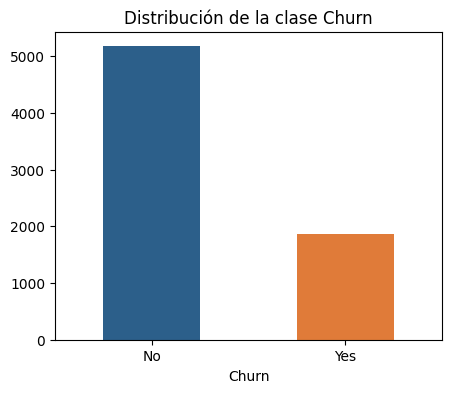

In [8]:
print(df_t.groupby('Churn').size())
print()
print((df_t['Churn'].value_counts(normalize=True) * 100).round(1))

df_t['Churn'].value_counts().plot(kind='bar', color=[AZUL, NARANJA], rot=0, figsize=(5, 4))
plt.title('Distribución de la clase Churn')
plt.show()

La clase está desbalanceada. Se va el **26,5%** de los clientes, así que un modelo que diga siempre No ya acierta el **73,5%** sin detectar ninguna baja. Por eso el accuracy solo no alcanza para comparar modelos, y en A5 usamos el AUC.

Para ver qué grupos tienen más riesgo calculamos el porcentaje de bajas en cada categoría. La línea naranja es el promedio general.

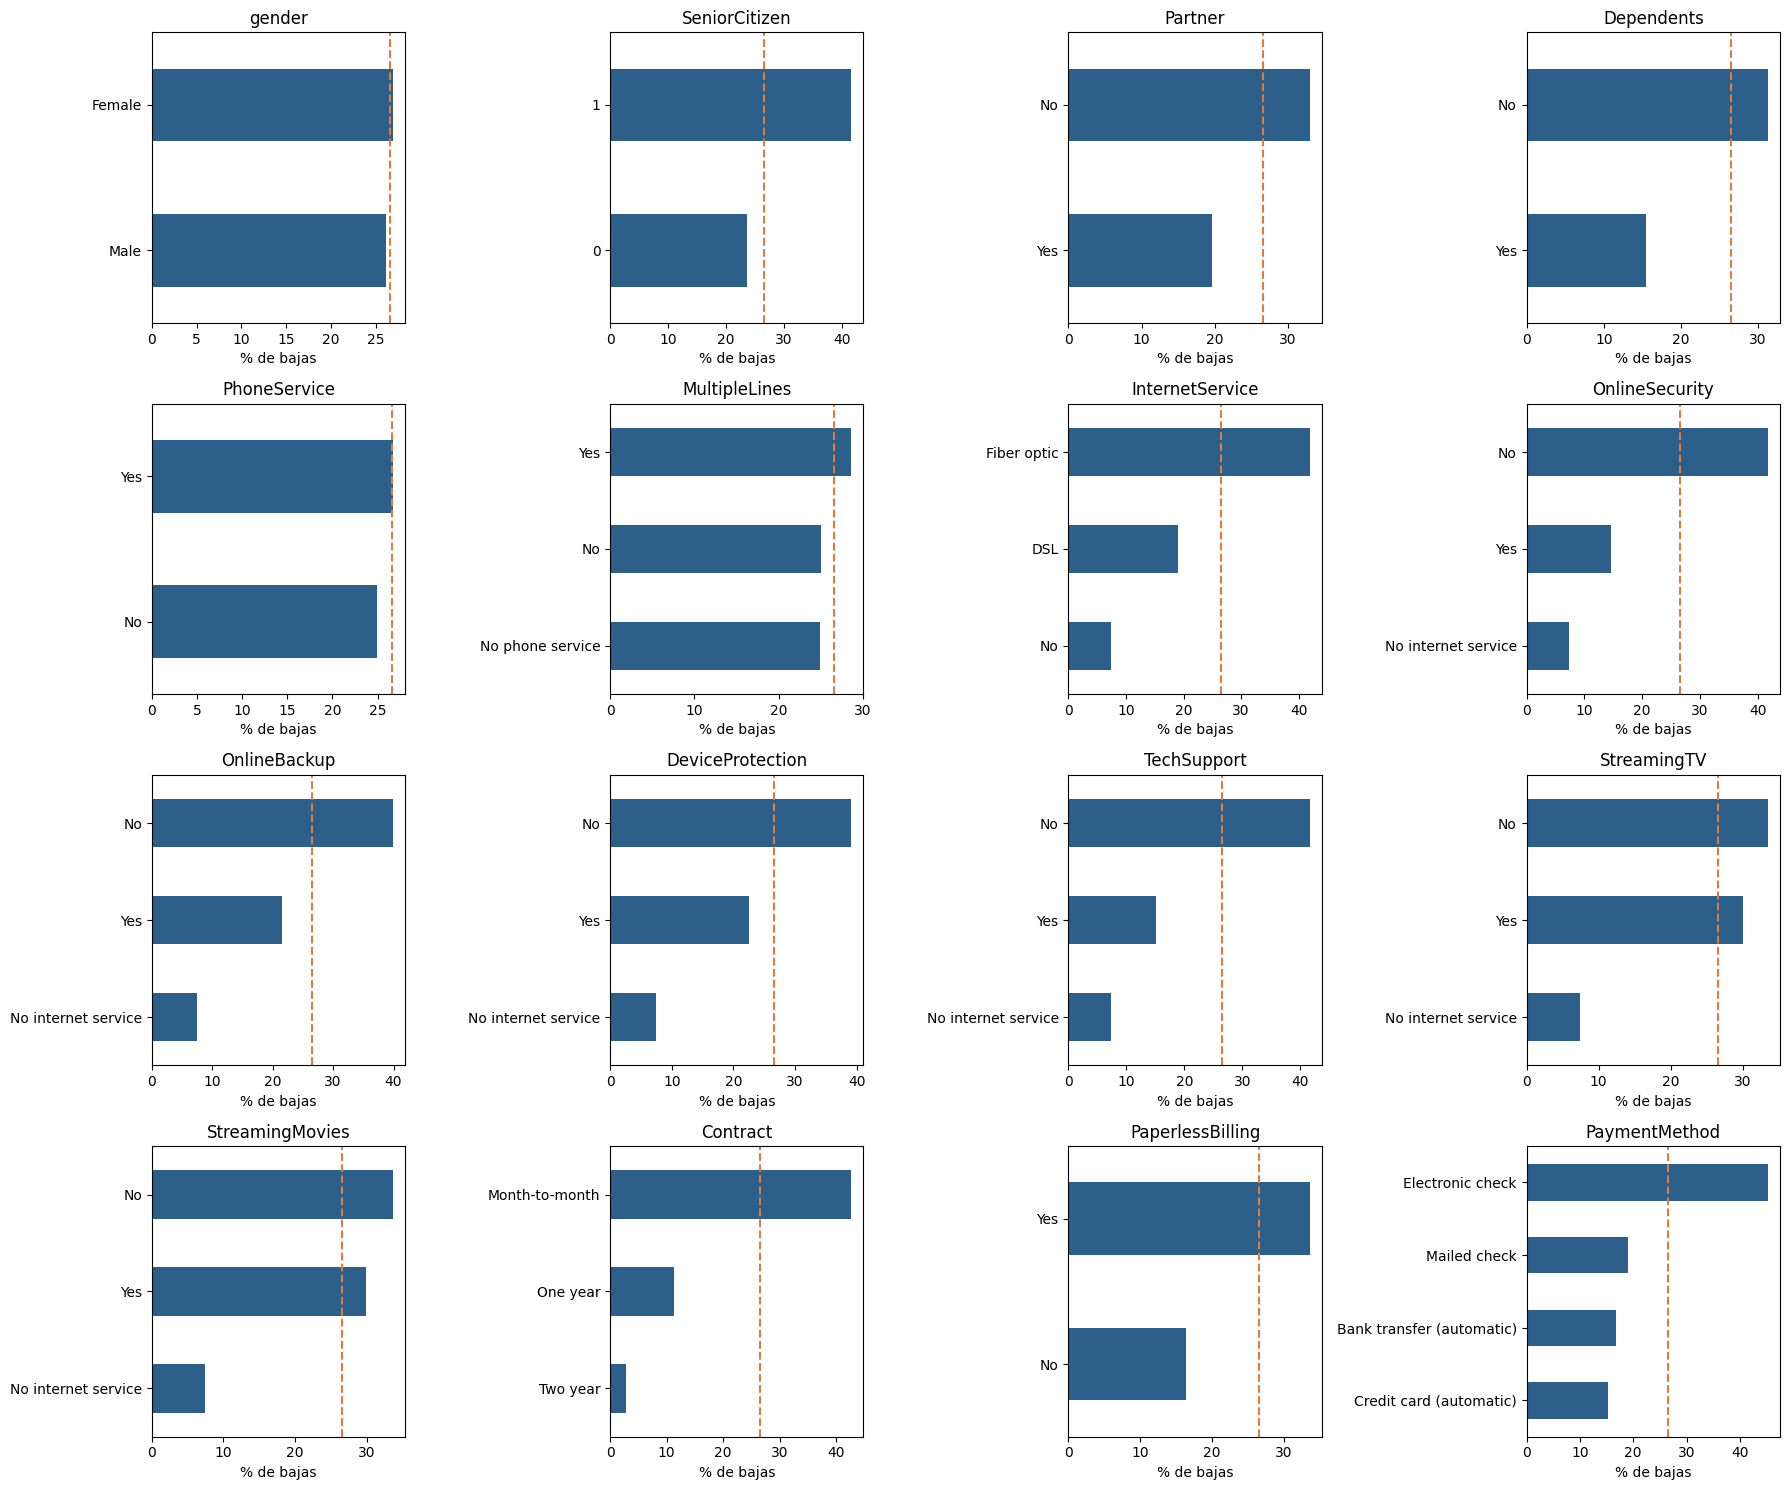

In [9]:
aux = df_t.copy()
aux['baja'] = (aux['Churn'] == 'Yes').astype(int) * 100

plt.figure(figsize=(18, 15))
for i, col in enumerate(cat_t):
    plt.subplot(4, 4, i + 1)
    aux.groupby(col)['baja'].mean().sort_values().plot(kind='barh', color=AZUL)
    plt.axvline(aux['baja'].mean(), color=NARANJA, linestyle='--')
    plt.title(col)
    plt.xlabel('% de bajas')
    plt.ylabel('')
plt.tight_layout()
plt.show()

* **Contract** es lo que más diferencia. Con contrato mes a mes se va el **43%**, con contrato de 1 año el 11% y con 2 años menos del 3%.
* En **InternetService**, con fibra óptica se va el **42%**, con DSL el 19% y sin internet el 7%.
* En **PaymentMethod**, con cheque electrónico se va el **45%** y con pago automático entre 15% y 17%.
* No tener **OnlineSecurity** ni **TechSupport** también se asocia a más bajas. Los mayores de 65 años se van más (42% contra 24%).
* **gender** y **PhoneService** casi no cambian la tasa, así que probablemente aporten poco.

### A2.4 Asimetría

In [10]:
df_t[num_t].skew()

tenure            0.240
MonthlyCharges   -0.221
TotalCharges      0.962
dtype: float64

Tomamos como asimetría baja un valor menor a 0,5 en valor absoluto, moderada entre 0,5 y 1 y fuerte por encima de 1. **TotalCharges** tiene asimetría positiva moderada (**0,96**). **tenure** y **MonthlyCharges** son casi simétricas, aunque los histogramas muestran que no tienen forma de campana.

### A2.5 Histogramas y gráficos de densidad

En la fila de abajo cada clase tiene su propia curva de densidad, para comparar la forma aunque haya muchos menos clientes en la clase Yes.

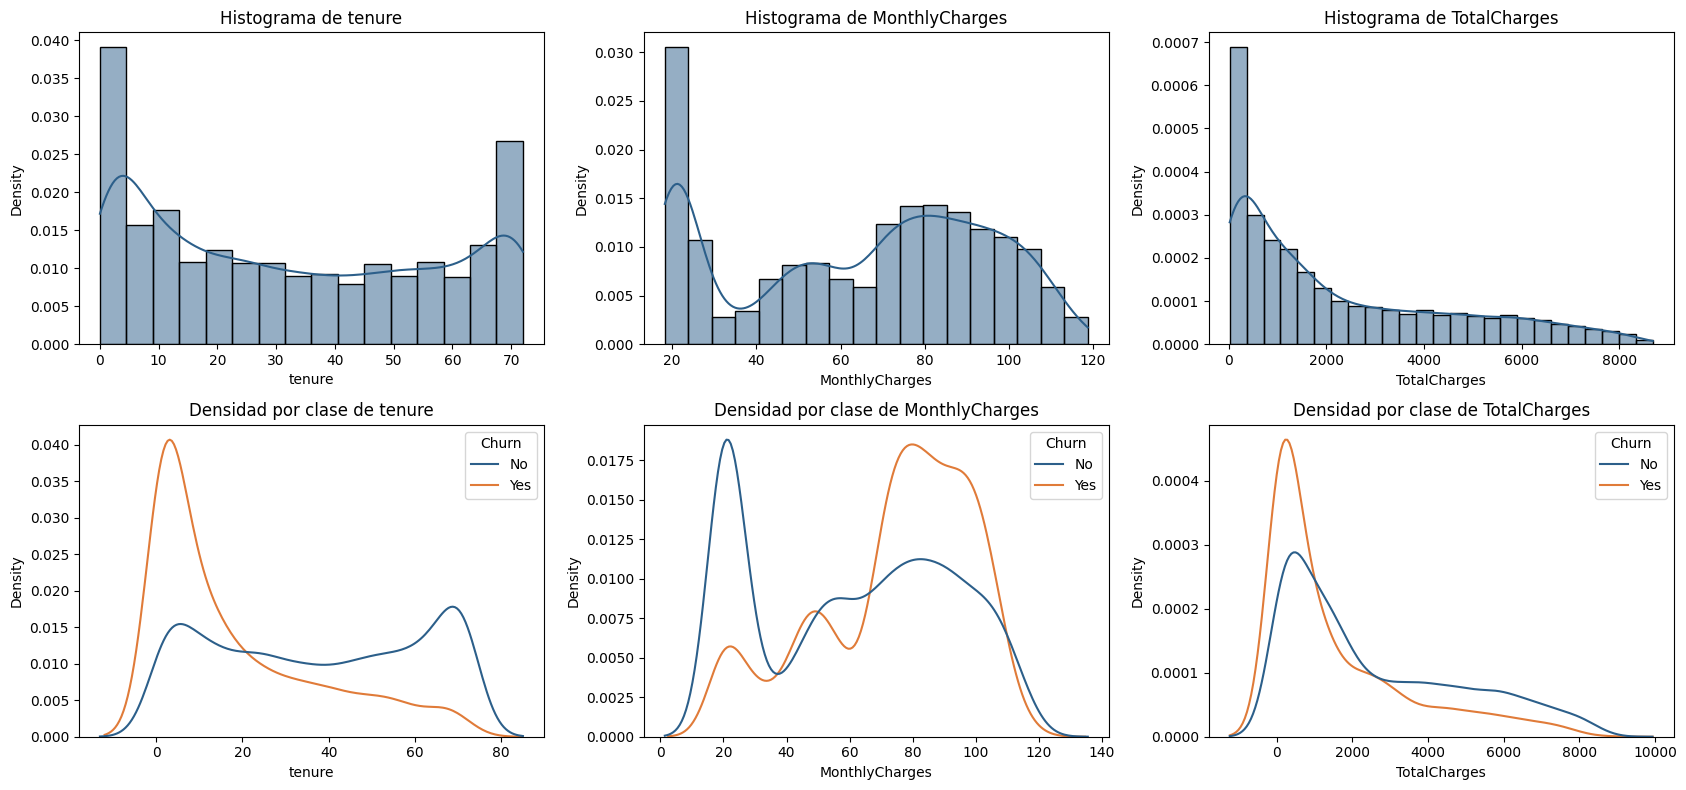

In [11]:
fig, axs = plt.subplots(2, 3, figsize=(17, 8))
for i, col in enumerate(num_t):
    sns.histplot(df_t[col], ax=axs[0, i], stat='density', kde=True, color=AZUL)
    axs[0, i].set_title('Histograma de ' + col)
    sns.kdeplot(data=df_t, x=col, hue='Churn', ax=axs[1, i], common_norm=False,
                palette={'No': AZUL, 'Yes': NARANJA})
    axs[1, i].set_title('Densidad por clase de ' + col)
plt.tight_layout()
plt.show()

* **tenure** tiene forma de U, con muchos clientes nuevos y muchos muy antiguos. En la densidad por clase se ve que las bajas se concentran en los primeros meses.
* **MonthlyCharges** tiene un pico cerca de 20 dólares (clientes que solo tienen teléfono) y otra zona entre 70 y 100. Los que se van pagan más por mes.
* **TotalCharges** tiene la cola larga hacia la derecha. Los que se van tienen un total bajo porque se van temprano.

### A2.6 Matriz de correlación

Para incluir las categóricas, en una copia del dataset pasamos las variables a 0 y 1 con variables dummy. La codificación definitiva se hace en A3.

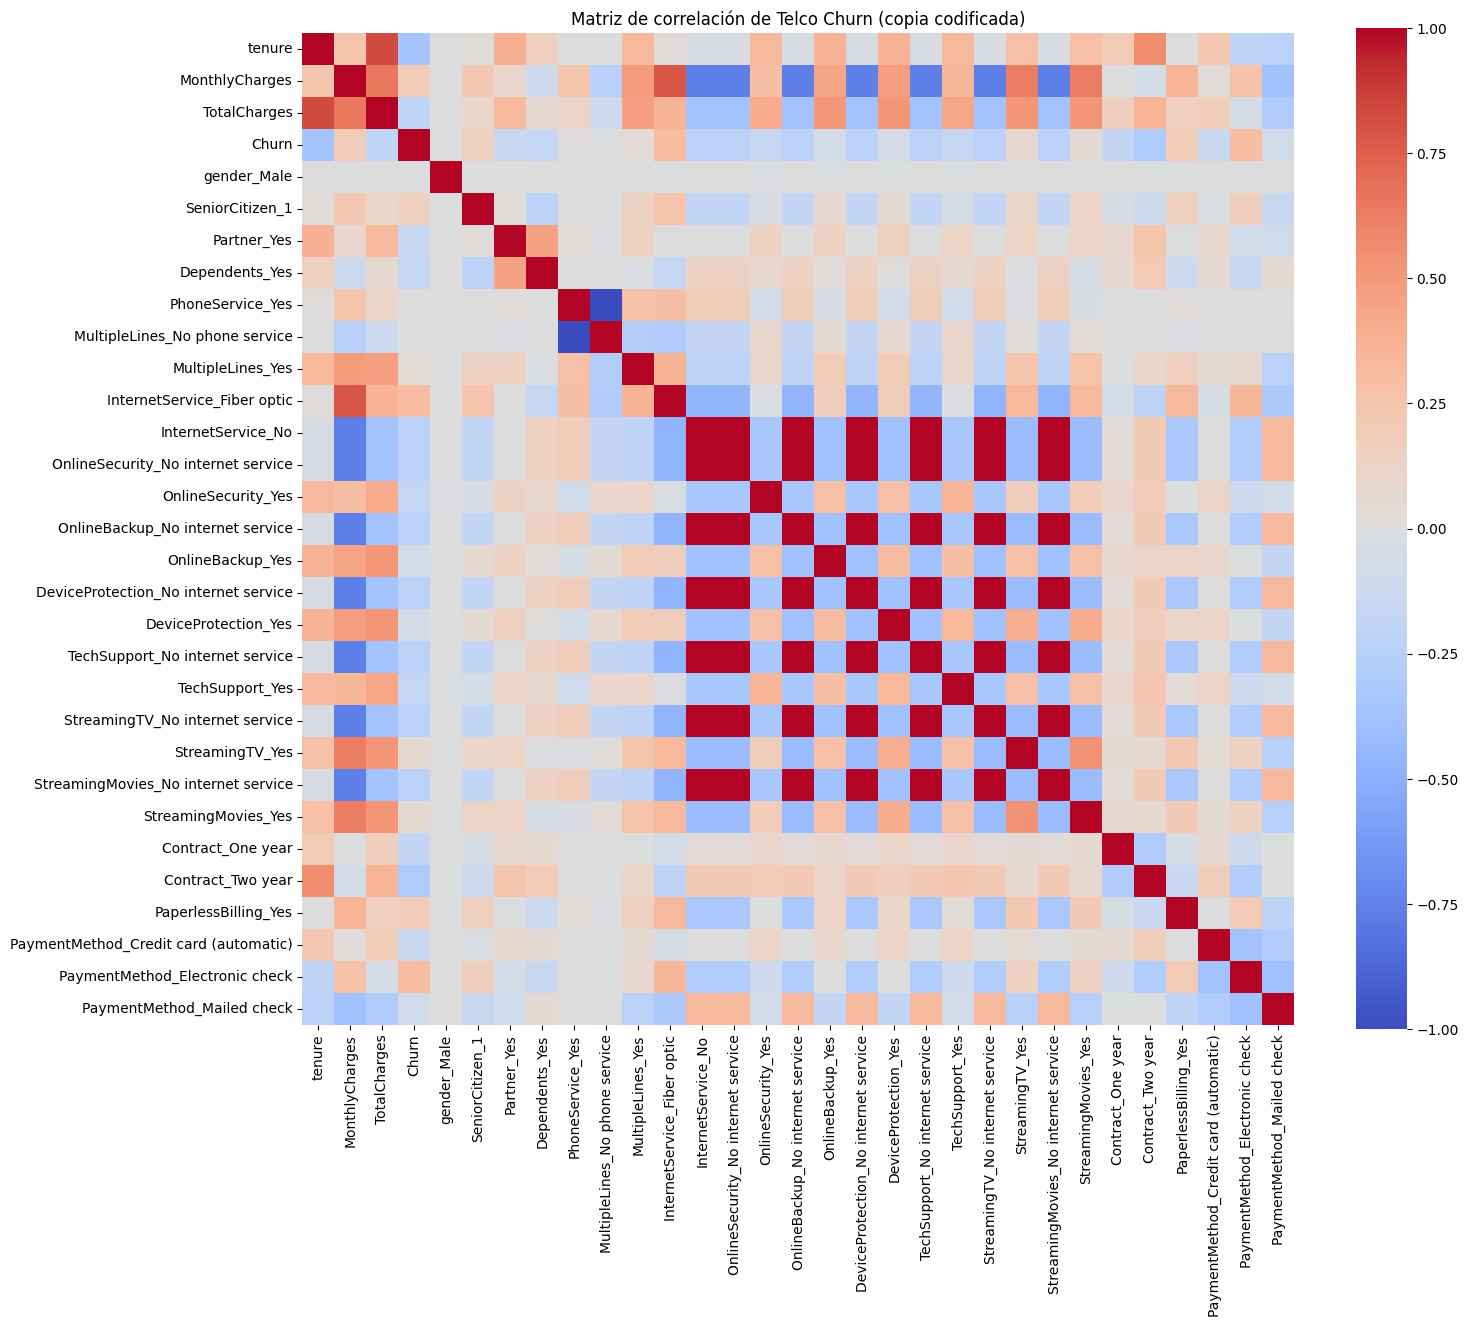

In [12]:
df_corr = df_t.drop(columns='customerID').copy()
df_corr['Churn'] = (df_corr['Churn'] == 'Yes').astype(int)
df_corr = pd.get_dummies(df_corr, columns=cat_t, drop_first=True, dtype=int)
correlacion_t = df_corr.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(correlacion_t, vmin=-1, vmax=1, cmap='coolwarm', square=True)
plt.title('Matriz de correlación de Telco Churn (copia codificada)')
plt.show()

In [13]:
correlacion_t['Churn'].drop('Churn').sort_values()

tenure                                  -0.352
Contract_Two year                       -0.302
OnlineSecurity_No internet service      -0.228
OnlineBackup_No internet service        -0.228
TechSupport_No internet service         -0.228
StreamingMovies_No internet service     -0.228
DeviceProtection_No internet service    -0.228
InternetService_No                      -0.228
StreamingTV_No internet service         -0.228
TotalCharges                            -0.199
Contract_One year                       -0.178
OnlineSecurity_Yes                      -0.171
TechSupport_Yes                         -0.165
Dependents_Yes                          -0.164
Partner_Yes                             -0.150
PaymentMethod_Credit card (automatic)   -0.134
PaymentMethod_Mailed check              -0.092
OnlineBackup_Yes                        -0.082
DeviceProtection_Yes                    -0.066
MultipleLines_No phone service          -0.012
gender_Male                             -0.009
PhoneService_

In [14]:
# Pares de variables de entrada con correlación mayor a 0.75 (triángulo superior, como en la clase de Feature Selection)
corr_matriz = df_corr.drop(columns='Churn').corr().abs()
triang_sup = corr_matriz.where(np.triu(np.ones(corr_matriz.shape), k=1).astype(np.bool_))

for columna in triang_sup.columns:
    altas = triang_sup[columna][triang_sup[columna] > 0.75]
    for fila, valor in altas.items():
        print(f'{fila} y {columna}: {valor:.2f}')

tenure y TotalCharges: 0.83
PhoneService_Yes y MultipleLines_No phone service: 1.00
MonthlyCharges y InternetService_Fiber optic: 0.79
MonthlyCharges y InternetService_No: 0.76
MonthlyCharges y OnlineSecurity_No internet service: 0.76
InternetService_No y OnlineSecurity_No internet service: 1.00
MonthlyCharges y OnlineBackup_No internet service: 0.76
InternetService_No y OnlineBackup_No internet service: 1.00
OnlineSecurity_No internet service y OnlineBackup_No internet service: 1.00
MonthlyCharges y DeviceProtection_No internet service: 0.76
InternetService_No y DeviceProtection_No internet service: 1.00
OnlineSecurity_No internet service y DeviceProtection_No internet service: 1.00
OnlineBackup_No internet service y DeviceProtection_No internet service: 1.00
MonthlyCharges y TechSupport_No internet service: 0.76
InternetService_No y TechSupport_No internet service: 1.00
OnlineSecurity_No internet service y TechSupport_No internet service: 1.00
OnlineBackup_No internet service y TechS

* Lo que más se relaciona con la baja es **tenure** (**-0,35**, a más antigüedad menos bajas), la fibra óptica (**0,31**), el contrato de 2 años (**-0,30**) y el pago con cheque electrónico (**0,30**).
* **tenure** y **TotalCharges** tienen una correlación de **0,83**. Tiene sentido, porque el total facturado es aproximadamente la antigüedad por el cargo mensual.
* Las columnas No internet service de los seis servicios tienen correlación **1** entre sí y con InternetService_No. Repiten seis veces el mismo dato. Lo mismo pasa con No phone service de **MultipleLines** y **PhoneService**. Lo corregimos en la limpieza.
* **MonthlyCharges** y la fibra óptica tienen **0,79**, porque la fibra es el servicio más caro.

### A2.7 Matriz de dispersión por clase

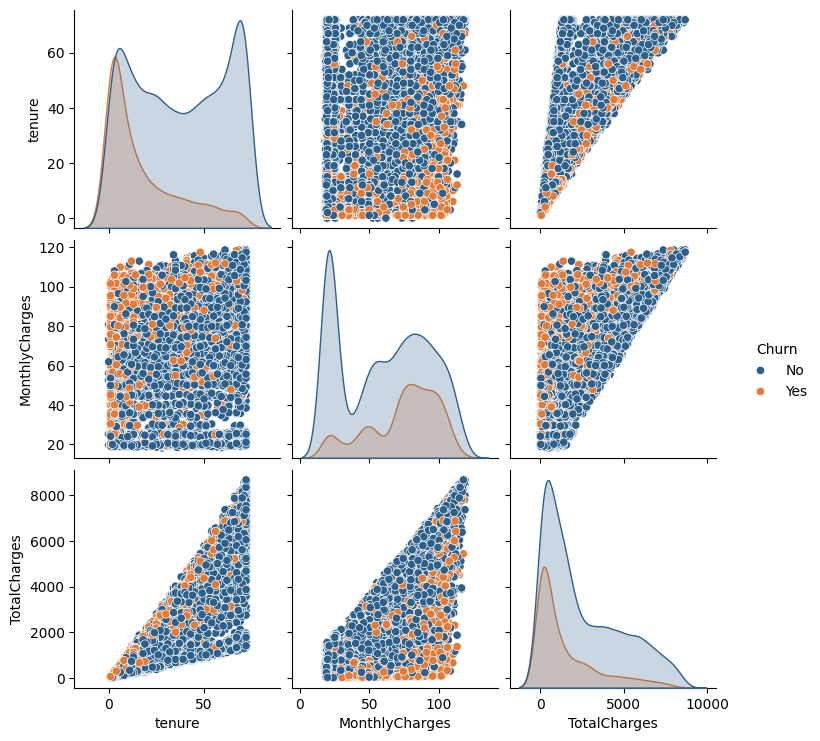

In [15]:
sns.pairplot(df_t[num_t + ['Churn']], hue='Churn', palette={'No': AZUL, 'Yes': NARANJA})
plt.show()

* En **tenure** contra **MonthlyCharges**, las bajas se juntan en la zona de poca antigüedad y cargo mensual alto.
* **tenure** contra **TotalCharges** muestra la relación casi exacta entre las dos. Los puntos forman un abanico cuya pendiente es el cargo mensual.
* Las clases se superponen bastante. Ninguna variable numérica sola alcanza para separar a los que se van.

### A2.8 Boxplots por clase

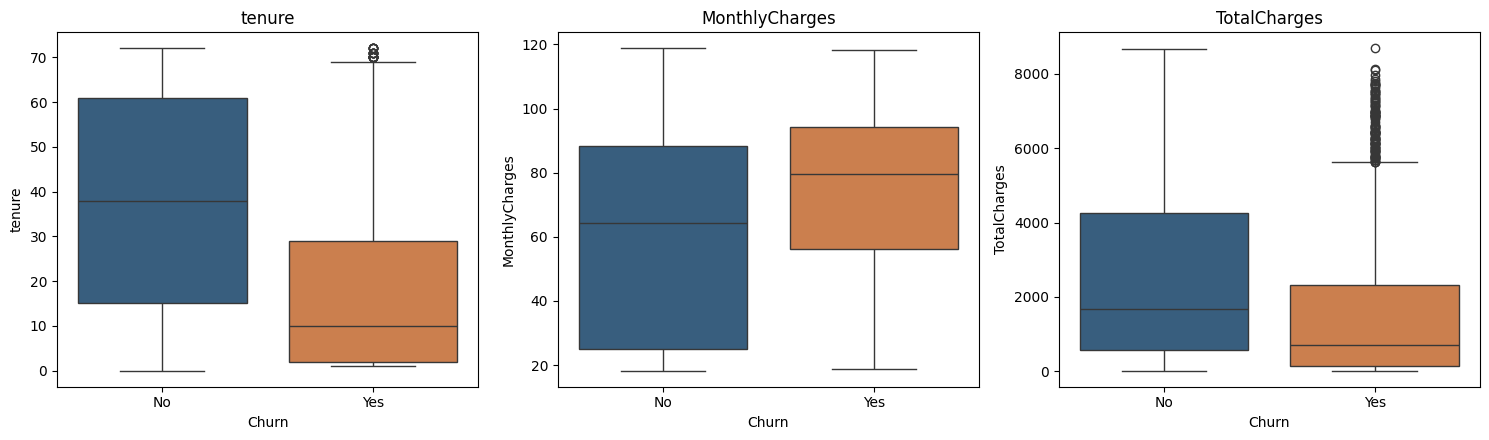

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for i, col in enumerate(num_t):
    sns.boxplot(df_t, x='Churn', y=col, ax=axs[i], hue='Churn', palette={'No': AZUL, 'Yes': NARANJA})
    axs[i].set_title(col)
plt.tight_layout()
plt.show()

df_t.groupby('Churn')[num_t].median()

Los clientes que se van tienen una antigüedad mediana de **10** meses, contra **38** de los que se quedan, y pagan más por mes (mediana de **80** dólares contra **64**). En la clase Yes hay algunos puntos por encima del bigote en **tenure** y **TotalCharges**. Son los pocos clientes antiguos que igual se fueron.

### A2.9 Valores faltantes, duplicados, atípicos e inconsistencias

In [17]:
print('Faltantes por columna')
print(df_t.isna().sum())

print('\nFilas duplicadas:', df_t.duplicated().sum())
print('Filas duplicadas sin contar customerID:', df_t.drop(columns='customerID').duplicated().sum())
print('customerID repetidos:', df_t['customerID'].duplicated().sum())

q1 = df_t[num_t].quantile(0.25)
q3 = df_t[num_t].quantile(0.75)
iqr = q3 - q1
print('\nValores atípicos según el rango intercuartílico (criterio de los bigotes del boxplot)')
print(((df_t[num_t] < q1 - 1.5 * iqr) | (df_t[num_t] > q3 + 1.5 * iqr)).sum())

print('\nCategorías de cada variable')
for col in cat_t:
    print(col, list(df_t[col].unique()))

Faltantes por columna
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Filas duplicadas: 0
Filas duplicadas sin contar customerID: 22
customerID repetidos: 0

Valores atípicos según el rango intercuartílico (criterio de los bigotes del boxplot)
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

Categorías de cada variable
gender ['Female', 'Male']
SeniorCitizen [np.int64(0), np.int64(1)]
Partner ['Yes', 'No']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No phone service', 'No', 'Yes']
InternetService 

#### Decisión
1. **customerID** es solo un identificador y no ayuda a predecir. La eliminamos.
2. Los 11 faltantes de **TotalCharges** son clientes con **tenure** igual a 0. Los reemplazamos por 0, porque todavía no se les facturó nada. Usar la media (2.283 dólares) le asignaría a un cliente nuevo lo que factura un cliente con años de antigüedad.
3. No hay filas ni clientes repetidos. Sin contar el ID hay 22 filas iguales, pero son clientes distintos con el mismo perfil (por ejemplo, clientes nuevos con el plan más básico). Las dejamos porque no son errores de carga.
4. No internet service y No phone service repiten información que ya está en **InternetService** y **PhoneService**. Las reemplazamos por No. Así esas 7 variables quedan binarias y desaparecen las correlaciones perfectas.
5. Según el rango intercuartílico no hay atípicos en las numéricas, así que no hace falta tratarlos.

In [18]:
df_t = df_t.drop(columns='customerID')
df_t['TotalCharges'] = df_t['TotalCharges'].fillna(0)

servicios = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
print('Antes')
print(df_t['OnlineSecurity'].value_counts())
print(df_t['MultipleLines'].value_counts())
df_t[servicios] = df_t[servicios].replace('No internet service', 'No')
df_t['MultipleLines'] = df_t['MultipleLines'].replace('No phone service', 'No')
print('\nDespués')
print(df_t['OnlineSecurity'].value_counts())
print(df_t['MultipleLines'].value_counts())

print('\nFaltantes que quedan:', df_t.isna().sum().sum())
print('Dimensiones después de la limpieza:', df_t.shape)

Antes
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Después
OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64
MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64

Faltantes que quedan: 0
Dimensiones después de la limpieza: (7043, 20)


## A3. Preprocesamiento de datos

### A3.1 Codificación de variables categóricas y de la clase

| Variables | Técnica | Motivo |
|---|---|---|
| gender, Partner, Dependents, PhoneService, MultipleLines, los 6 servicios de internet y PaperlessBilling | Label Encoding | Tienen 2 categorías, así que alcanza con 0 y 1 |
| SeniorCitizen | Ninguna | Ya viene en 0 y 1 |
| InternetService, Contract y PaymentMethod | One-Hot Encoding con drop_first=True | Tienen 3 o 4 categorías sin un orden numérico. Con 0, 1, 2 y 3 el modelo supondría, por ejemplo, que una forma de pago vale más que otra |
| Churn (clase) | Label Encoding | No pasa a 0 y Yes a 1, porque la clase positiva es darse de baja |

drop_first=True elimina una columna por variable porque es redundante. Si todas las dummies valen 0, el cliente está en la categoría que falta.

No usamos Target Encoding porque conviene cuando una variable tiene muchas categorías, y acá la que más tiene son 4. Label y One-Hot no usan la variable objetivo, así que se pueden aplicar antes de separar train y test sin filtrar información.

In [19]:
binarias_t = [col for col in cat_t if df_t[col].nunique() == 2 and col != 'SeniorCitizen']
multicat_t = [col for col in cat_t if df_t[col].nunique() > 2]
print('Label Encoding:', binarias_t)
print('One-Hot Encoding:', multicat_t)

df_t_cod = df_t.copy()
for col in binarias_t:
    df_t_cod[col] = LabelEncoder().fit_transform(df_t_cod[col])
df_t_cod = pd.get_dummies(df_t_cod, columns=multicat_t, drop_first=True, dtype=int)

le_churn = LabelEncoder()
df_t_cod['Churn'] = le_churn.fit_transform(df_t_cod['Churn'])
print('Clase:', le_churn.classes_, 'pasan a', le_churn.transform(le_churn.classes_))
print('Dimensiones:', df_t.shape, 'antes y', df_t_cod.shape, 'después')

Label Encoding: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']
One-Hot Encoding: ['InternetService', 'Contract', 'PaymentMethod']
Clase: ['No' 'Yes'] pasan a [0 1]
Dimensiones: (7043, 20) antes y (7043, 24) después


In [20]:
# Antes de codificar
df_t.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [21]:
# Después de codificar
df_t_cod.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,0,0,0,0,0,0,1


### A3.2 División en entrenamiento y prueba

Separamos 70% para entrenamiento y 30% para prueba. Usamos stratify para que las dos partes tengan el mismo porcentaje de bajas, porque con clases desbalanceadas un reparto al azar podría dejar a una de las partes con menos bajas. El conjunto de prueba no se vuelve a usar hasta la evaluación final (A8).

In [22]:
X_t = df_t_cod.drop(columns='Churn')
y_t = df_t_cod['Churn']
features_t = X_t.columns.tolist()

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_t, y_t, test_size=0.3,
                                                            random_state=SEMILLA, stratify=y_t)
print('Train:', X_train_t.shape, 'Test:', X_test_t.shape)
print(f'% de bajas en train: {y_train_t.mean() * 100:.1f}% y en test: {y_test_t.mean() * 100:.1f}%')

Train: (4930, 23) Test: (2113, 23)
% de bajas en train: 26.5% y en test: 26.5%


### A3.3 Transformación de las variables numéricas

Aplicamos dos transformaciones a las 3 numéricas, en este orden.
1. **Yeo-Johnson**, para corregir la asimetría de **TotalCharges**. Box-Cox no se puede usar porque solo acepta valores mayores a 0, y **tenure** y **TotalCharges** tienen ceros (los clientes nuevos).
2. **Estandarización**, para llevar las tres a media 0 y desvío 1. La regresión logística compara coeficientes, y KNN, SVM y PCA usan distancias o varianzas, así que una variable en miles de dólares dominaría sobre una en meses.

El orden importa porque primero se corrige la forma de la distribución y después se ajusta la escala. Si estandarizáramos primero, Yeo-Johnson cambiaría la escala otra vez. Las dos se ajustan solo con train y después se aplican a test. Las variables 0 y 1 no se transforman.

In [23]:
print('Valores menores o iguales a 0 en train')
print((X_train_t[num_t] <= 0).sum())

Valores menores o iguales a 0 en train
tenure            7
MonthlyCharges    0
TotalCharges      7
dtype: int64


In [24]:
# 1ro Yeo-Johnson (ajustado solo con train)
yeo_t = PowerTransformer(method='yeo-johnson', standardize=False).fit(X_train_t[num_t])
X_train_t_tr = X_train_t.copy()
X_test_t_tr = X_test_t.copy()
X_train_t_tr[num_t] = yeo_t.transform(X_train_t[num_t])
X_test_t_tr[num_t] = yeo_t.transform(X_test_t[num_t])

# 2do estandarización (ajustada solo con train)
escala_t = StandardScaler().fit(X_train_t_tr[num_t])
X_train_t_tr[num_t] = escala_t.transform(X_train_t_tr[num_t])
X_test_t_tr[num_t] = escala_t.transform(X_test_t_tr[num_t])

print('Lambdas de Yeo-Johnson:', yeo_t.lambdas_.round(3))

Lambdas de Yeo-Johnson: [0.444 0.923 0.253]


In [25]:
# Antes de transformar (train)
X_train_t[num_t].head()

,tenure,MonthlyCharges,TotalCharges
5557,5,80.20,384.25
2270,3,86.85,220.95
6930,3,75.15,216.75
2257,60,80.55,4847.05
898,12,98.90,1120.95


In [26]:
# Después de transformar (train)
X_train_t_tr[num_t].head()

,tenure,MonthlyCharges,TotalCharges
5557,-1.171,0.515,-0.798
2270,-1.375,0.728,-1.074
6930,-1.375,0.352,-1.083
2257,1.050,0.526,1.103
898,-0.666,1.112,-0.140


In [27]:
pd.DataFrame({'media antes': X_train_t[num_t].mean(),
              'desvío antes': X_train_t[num_t].std(),
              'asimetría antes': X_train_t[num_t].skew(),
              'media después': X_train_t_tr[num_t].mean(),
              'desvío después': X_train_t_tr[num_t].std(),
              'asimetría después': X_train_t_tr[num_t].skew(),
              'media en test': X_test_t_tr[num_t].mean()}).round(3)

,media antes,desvío antes,asimetría antes,media después,desvío después,asimetría después,media en test
tenure,32.471,24.646,0.24,-0.0,1.0,-0.242,-0.011
MonthlyCharges,64.950,30.244,-0.22,0.0,1.0,-0.260,-0.020
TotalCharges,2301.798,2292.566,0.95,-0.0,1.0,-0.145,-0.017


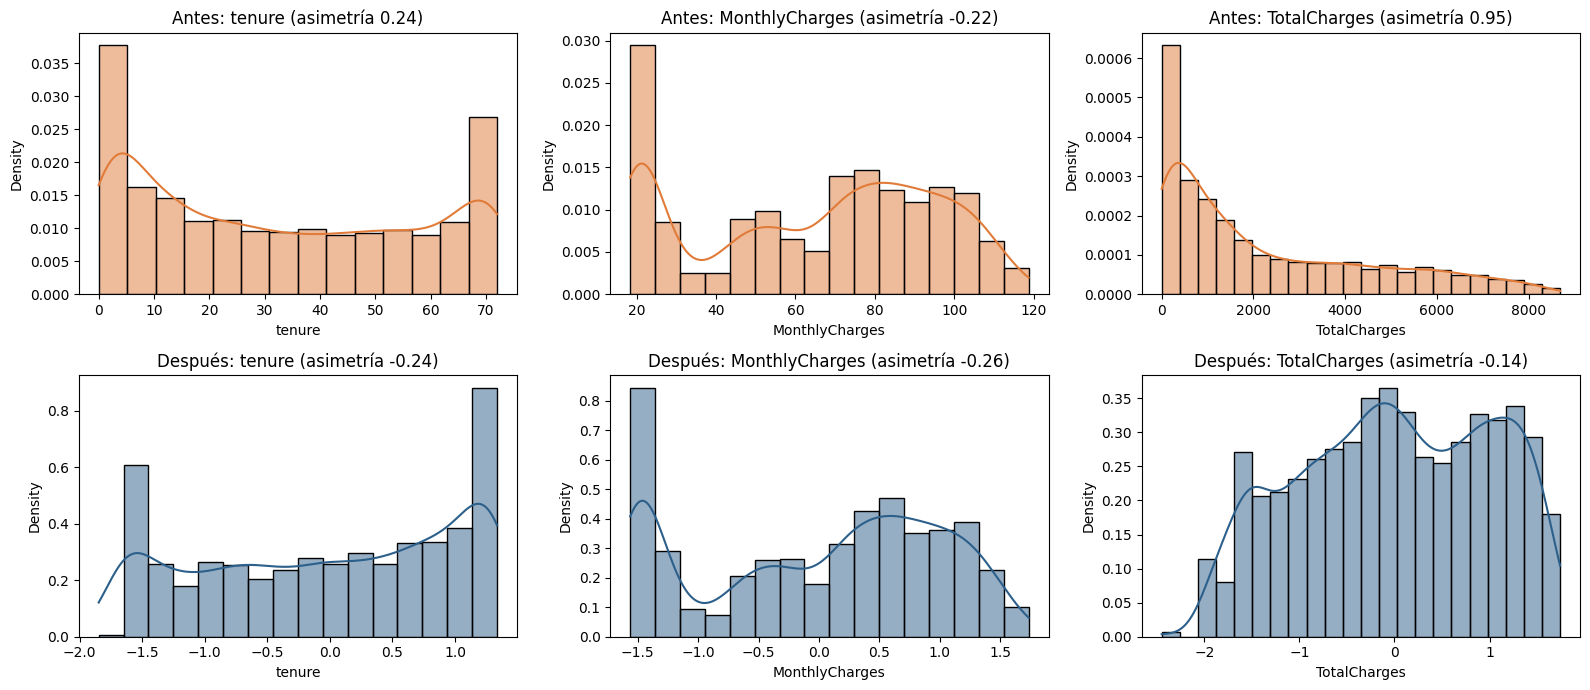

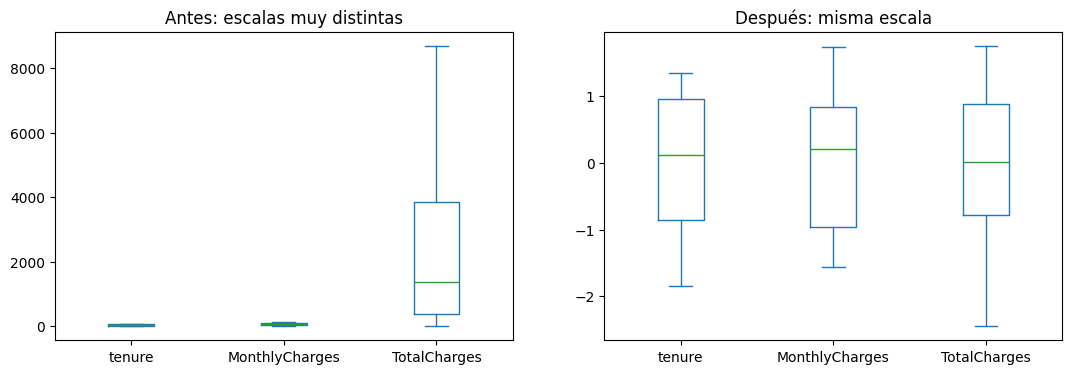

In [28]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7))
for i, col in enumerate(num_t):
    sns.histplot(X_train_t[col], ax=axs[0, i], stat='density', kde=True, color=NARANJA)
    axs[0, i].set_title(f'Antes: {col} (asimetría {X_train_t[col].skew():.2f})')
    sns.histplot(X_train_t_tr[col], ax=axs[1, i], stat='density', kde=True, color=AZUL)
    axs[1, i].set_title(f'Después: {col} (asimetría {X_train_t_tr[col].skew():.2f})')
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
X_train_t[num_t].plot(kind='box', ax=axs[0], title='Antes: escalas muy distintas')
X_train_t_tr[num_t].plot(kind='box', ax=axs[1], title='Después: misma escala')
plt.show()

Las tres numéricas quedaron con media 0 y desvío 1, y la asimetría de **TotalCharges** bajó de **0,95** a **-0,15**. En **tenure** y **MonthlyCharges** se mantienen los dos picos, porque corresponden a dos grupos reales de clientes y ninguna transformación los convierte en una campana. En test la media no da exactamente 0 porque se usaron los parámetros aprendidos en train, lo que confirma que no se usó información de test.

## A4. Selección de características y reducción de dimensiones

Después de codificar quedaron **23** variables. Para clasificación aplicamos **RFE** como técnica de Feature Selection (en regresión usamos otra técnica) y **PCA** sobre las 23 variables del modelo base, por separado de RFE.

### A4.1 Variables muy correlacionadas después de la limpieza

Como recomienda la clase de Feature Selection, antes de seleccionar revisamos si quedaron variables redundantes.

In [29]:
corr_train = X_train_t.corr().abs()
triang_sup = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(np.bool_))

for columna in triang_sup.columns:
    altas = triang_sup[columna][triang_sup[columna] > 0.75]
    for fila, valor in altas.items():
        print(f'{fila} y {columna}: {valor:.2f}')

tenure y TotalCharges: 0.83
MonthlyCharges y InternetService_Fiber optic: 0.79
MonthlyCharges y InternetService_No: 0.76


Las correlaciones perfectas entre servicios desaparecieron con la limpieza. Quedan **tenure** con **TotalCharges** (**0,83**) y **MonthlyCharges** con el tipo de internet (**0,79** y **0,76**). No eliminamos ninguna a mano, porque cada una tiene algo de información propia (el cargo también depende de los servicios adicionales). Dejamos que RFE decida.

### A4.2 Feature Selection con RFE

RFE entrena la regresión logística con todas las variables, saca la que tiene el coeficiente más chico en valor absoluto y repite hasta quedarse con la cantidad pedida. La elegimos porque usa directamente el modelo lineal que pide la consigna. Como compara coeficientes, se aplica sobre los datos ya estandarizados.

RFE necesita que le digamos cuántas variables conservar. Para no elegir a ojo, probamos de 1 a 23 y medimos el AUC con K-Fold de 10 particiones sobre train.

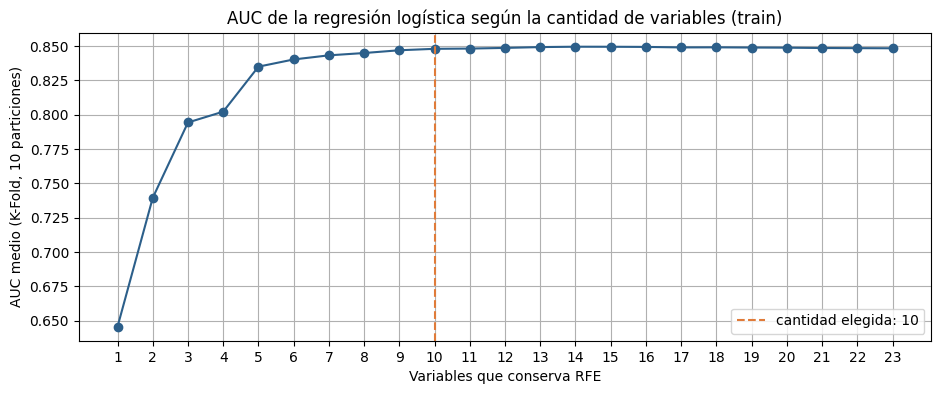

Mejor AUC: 0.8495 con 14 variables
Elegimos 10 variables, con AUC 0.8480


In [30]:
kfold = KFold(n_splits=10, shuffle=True, random_state=SEMILLA)

cantidades = range(1, len(features_t) + 1)
auc_medio = []
for n in cantidades:
    rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=n).fit(X_train_t_tr, y_train_t)
    columnas = X_train_t_tr.columns[rfe.support_]
    resultados = cross_val_score(LogisticRegression(max_iter=1000), X_train_t_tr[columnas], y_train_t,
                                 cv=kfold, scoring='roc_auc')
    auc_medio.append(resultados.mean())

# Elegimos la menor cantidad de variables con un AUC a menos de 0.002 del mejor
mejor_auc = max(auc_medio)
for n, auc in zip(cantidades, auc_medio):
    if auc >= mejor_auc - 0.002:
        n_rfe = n
        break

plt.figure(figsize=(11, 4))
plt.plot(cantidades, auc_medio, marker='o', color=AZUL)
plt.axvline(n_rfe, color=NARANJA, linestyle='--', label=f'cantidad elegida: {n_rfe}')
plt.xticks(cantidades)
plt.xlabel('Variables que conserva RFE')
plt.ylabel('AUC medio (K-Fold, 10 particiones)')
plt.title('AUC de la regresión logística según la cantidad de variables (train)')
plt.legend()
plt.grid(True)
plt.show()

print(f'Mejor AUC: {mejor_auc:.4f} con {auc_medio.index(mejor_auc) + 1} variables')
print(f'Elegimos {n_rfe} variables, con AUC {auc_medio[n_rfe - 1]:.4f}')

In [31]:
rfe_t = RFE(LogisticRegression(max_iter=1000), n_features_to_select=n_rfe).fit(X_train_t_tr, y_train_t)
sel_rfe_t = X_train_t_tr.columns[rfe_t.support_].tolist()

print(f'RFE conserva {len(sel_rfe_t)} de {len(features_t)} variables:')
print(sel_rfe_t)
pd.DataFrame({'ranking (1 = se conserva)': rfe_t.ranking_}, index=features_t).sort_values('ranking (1 = se conserva)')

RFE conserva 10 de 23 variables:
['MultipleLines', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'TotalCharges', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Electronic check']


,ranking (1 = se conserva)
MultipleLines,1
PaperlessBilling,1
TotalCharges,1
StreamingTV,1
StreamingMovies,1
Contract_One year,1
InternetService_No,1
InternetService_Fiber optic,1
Contract_Two year,1
PaymentMethod_Electronic check,1


* El AUC sube rápido hasta unas 8 variables y después se estabiliza. Las diferencias que siguen son de milésimas.
* El mejor AUC (**0,8495**) se da con 14 variables, pero con **10** queda a menos de 0,002. Elegimos 10 porque, entre dos modelos que rinden igual, conviene el más simple.
* RFE conserva lo que el EDA mostraba como importante, que es el tipo de contrato, la fibra óptica y el cheque electrónico. Las últimas del ranking son **Partner** y **gender**, que en el EDA casi no cambiaban la tasa de baja.
* RFE se queda con **TotalCharges** y descarta **tenure** y **MonthlyCharges**. Las tres están muy relacionadas, así que con una de ellas el modelo ya tiene casi toda esa información.

### A4.3 Reducción de dimensiones con PCA

PCA no elige variables. Crea componentes nuevas, que son combinaciones de todas las variables, ordenadas según cuánta varianza explican. Lo aplicamos sobre las **23** variables del modelo base y no sobre las que eligió RFE, como pide la consigna.

Antes de PCA estandarizamos las 23 variables, también las de 0 y 1, igual que en la clase de PCA. Una variable 0 y 1 tiene una varianza mucho menor que una numérica estandarizada, y sin este paso PCA casi la ignoraría. Conservamos las componentes que explican el 90% de la varianza.

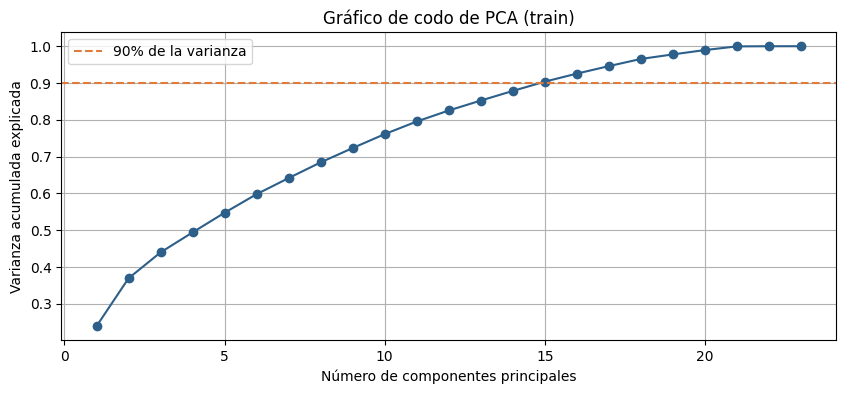

Componentes para explicar el 90% de la varianza: 15 de 23
Varianza de las tres primeras: [0.239 0.13  0.07 ]


In [32]:
escala_pca_t = StandardScaler().fit(X_train_t_tr)
X_train_t_esc = escala_pca_t.transform(X_train_t_tr)
X_test_t_esc = escala_pca_t.transform(X_test_t_tr)

pca_todas = PCA().fit(X_train_t_esc)
varianza_acumulada = np.cumsum(pca_todas.explained_variance_ratio_)
n_pca_t = (varianza_acumulada < 0.90).sum() + 1

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', color=AZUL)
plt.axhline(y=0.9, color=NARANJA, linestyle='--', label='90% de la varianza')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza acumulada explicada')
plt.title('Gráfico de codo de PCA (train)')
plt.legend()
plt.grid(True)
plt.show()

print(f'Componentes para explicar el 90% de la varianza: {n_pca_t} de {len(features_t)}')
print('Varianza de las tres primeras:', pca_todas.explained_variance_ratio_[:3].round(3))

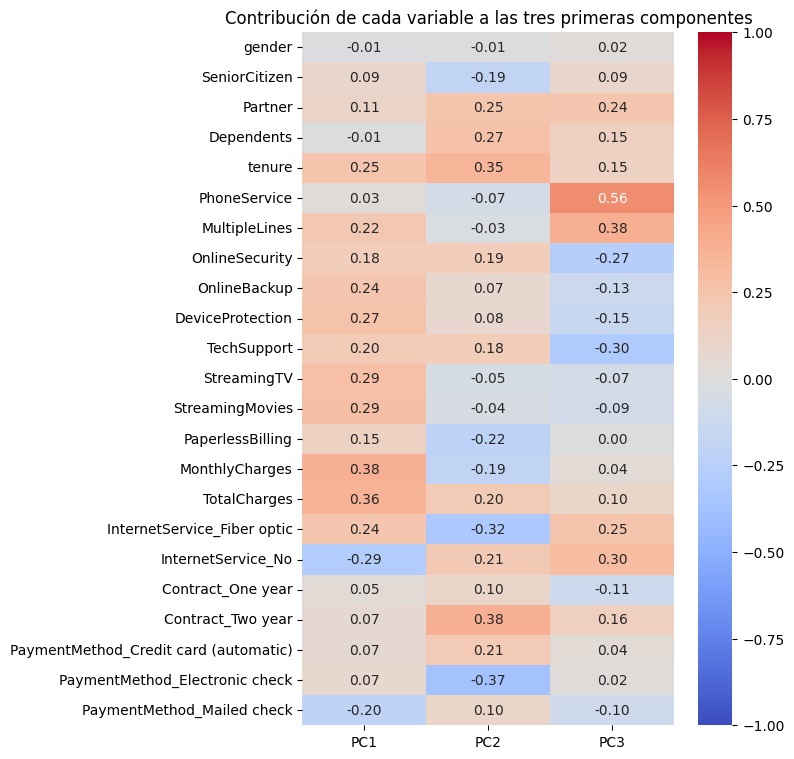

In [33]:
pca_t = PCA(n_components=n_pca_t).fit(X_train_t_esc)
X_train_t_pca = pca_t.transform(X_train_t_esc)
X_test_t_pca = pca_t.transform(X_test_t_esc)

plt.figure(figsize=(6, 9))
sns.heatmap(pca_t.components_[:3].T, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f',
            xticklabels=['PC1', 'PC2', 'PC3'], yticklabels=features_t)
plt.title('Contribución de cada variable a las tres primeras componentes')
plt.show()

* Hacen falta **15** componentes de 23 para llegar al 90% de la varianza. La reducción es moderada porque muchas variables 0 y 1 aportan información propia y están poco correlacionadas entre sí.
* La primera componente (**24%** de la varianza) junta el cargo mensual, el total facturado y los servicios de streaming, contra no tener internet. Resume cuántos servicios tiene el cliente y cuánto paga. La segunda explica el **13%**.
* La desventaja de PCA es que cada componente mezcla todas las variables, así que se pierde la interpretación. Por ejemplo, el contrato de 2 años deja de ser una columna.

## A5. Entrenamiento y comparación de modelos

Comparamos **LogisticRegression** (taxonomía lineal) con un modelo no lineal elegido por el grupo, cada uno con tres conjuntos de variables.

| Conjunto | Qué recibe el modelo |
|---|---|
| Base | Las 23 variables transformadas |
| RFE | Las 10 variables que eligió RFE |
| PCA | Las 15 componentes calculadas sobre las 23 variables del modelo base |

Son 6 modelos y todos se comparan igual, con K-Fold de 10 particiones sobre train y el mismo scoring en cross_val_score, **roc_auc**.

Elegimos roc_auc y no accuracy por el desbalance de clases. Decir siempre No ya da 73,5% de accuracy sin detectar ninguna baja. El AUC mide qué tan bien el modelo ordena a los clientes según su riesgo de irse (1 es perfecto y 0,5 es azar), sin depender de un umbral de decisión.

### A5.1 Elección del modelo no lineal

Probamos los clasificadores no lineales de la clase de Algoritmos de ML con su configuración por defecto, sobre el modelo base. La consigna aclara que no se optimizan hiperparámetros.

In [34]:
no_lineales_t = {'KNN': KNeighborsClassifier(),
                 'Naive Bayes': GaussianNB(),
                 'Árbol de decisión': DecisionTreeClassifier(random_state=SEMILLA),
                 'SVM': SVC()}

for nombre, modelo in no_lineales_t.items():
    resultados = cross_val_score(modelo, X_train_t_tr, y_train_t, cv=kfold, scoring='roc_auc')
    print(f'{nombre}: AUC {resultados.mean():.3f} (desv est +/- {resultados.std():.3f})')

KNN: AUC 0.791 (desv est +/- 0.022)
Naive Bayes: AUC 0.836 (desv est +/- 0.024)


Árbol de decisión: AUC 0.665 (desv est +/- 0.031)


SVM: AUC 0.799 (desv est +/- 0.028)


#### Decisión
Elegimos **Naive Bayes** (GaussianNB) como modelo no lineal.
* Es el no lineal con mejor AUC (**0,836**), por encima de SVM (0,799) y KNN (0,791).
* Casi no tiene hiperparámetros. Como en este TP no se optimizan, conviene un modelo que rinda bien tal como viene. El árbol sin límite de profundidad se sobreajusta (AUC 0,665), y KNN y SVM dependen mucho de sus hiperparámetros.
* Es rápido y tiene un enfoque distinto al de la regresión logística. Es probabilístico, se basa en el teorema de Bayes y supone que las variables son independientes entre sí.

### A5.2 Comparación de los 6 modelos

In [35]:
conjuntos_t = {f'Base ({len(features_t)} var.)': (X_train_t_tr, X_test_t_tr),
               f'RFE ({len(sel_rfe_t)} var.)': (X_train_t_tr[sel_rfe_t], X_test_t_tr[sel_rfe_t]),
               f'PCA ({n_pca_t} comp.)': (X_train_t_pca, X_test_t_pca)}
modelos_t = {'LogisticRegression': LogisticRegression(max_iter=1000),
             'GaussianNB': GaussianNB()}

folds_t = {}
filas = []
for nombre_conj, (X_train_conj, X_test_conj) in conjuntos_t.items():
    for nombre_mod, modelo in modelos_t.items():
        resultados = cross_val_score(modelo, X_train_conj, y_train_t, cv=kfold, scoring='roc_auc')
        folds_t[nombre_mod + '\n' + nombre_conj] = resultados
        filas.append([nombre_mod, nombre_conj, resultados.mean(), resultados.std()])

tabla_t = pd.DataFrame(filas, columns=['modelo', 'conjunto', 'AUC medio', 'desvío'])
tabla_t

,modelo,conjunto,AUC medio,desvío
0,LogisticRegression,Base (23 var.),0.848,0.017
1,GaussianNB,Base (23 var.),0.836,0.024
2,LogisticRegression,RFE (10 var.),0.848,0.019
3,GaussianNB,RFE (10 var.),0.829,0.027
4,LogisticRegression,PCA (15 comp.),0.847,0.018
5,GaussianNB,PCA (15 comp.),0.827,0.017


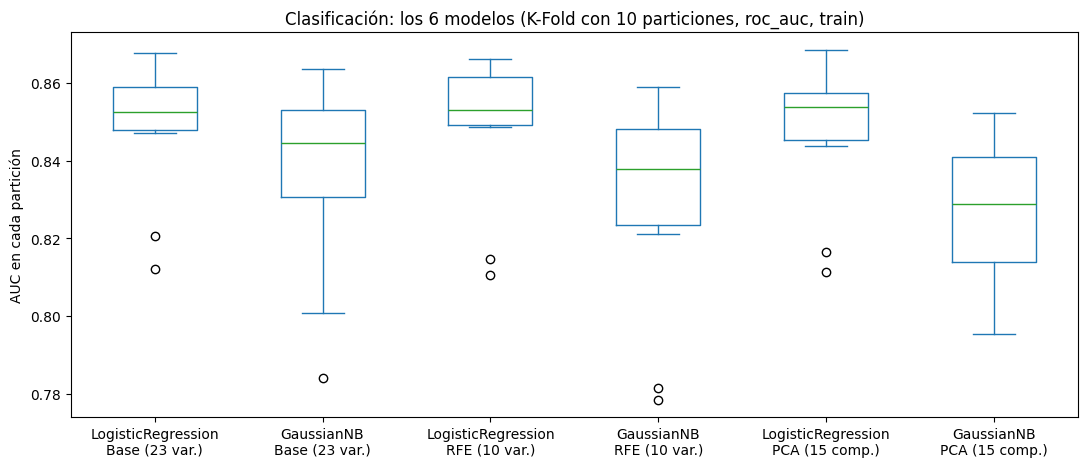

In [36]:
pd.DataFrame(folds_t).plot(kind='box', figsize=(13, 5))
plt.ylabel('AUC en cada partición')
plt.title('Clasificación: los 6 modelos (K-Fold con 10 particiones, roc_auc, train)')
plt.show()

* La regresión logística le gana a Naive Bayes con los tres conjuntos (**0,848**, **0,848** y **0,847**, contra 0,836, 0,829 y 0,827). La diferencia es menor que el desvío entre particiones, pero se repite en los tres casos.
* Para la regresión logística los tres conjuntos empatan, porque las diferencias son de una milésima. Lo que cambia es la cantidad de variables, 23 en el modelo base, **10** con RFE y 15 componentes con PCA.
* PCA no mejora y además hace perder la interpretación. Para Naive Bayes es el conjunto más flojo.

## A6. Optimización de hiperparámetros y selección del mejor modelo

Según la consigna, acá iría la optimización de hiperparámetros de los modelos más prometedores. Esa etapa no se realiza en este TP.

#### Decisión
Elegimos **LogisticRegression con las 10 variables de RFE**.
1. Comparte el mejor AUC de los 6 modelos (**0,848**) con la regresión logística sobre el modelo base, y PCA queda a una milésima.
2. Usa **10** variables en lugar de 23. Son menos datos para recolectar y mantener cuando el modelo esté en uso.
3. Sus coeficientes se pueden leer directamente, por ejemplo cuánto baja el riesgo un contrato de 2 años. Con PCA eso no se puede porque cada componente mezcla todas las variables.

## A7. Entrenamiento con el conjunto de entrenamiento completo

En la validación cruzada cada modelo se entrenó con el 90% de train. Ahora entrenamos el modelo elegido con todo train (**4.930** clientes).

In [37]:
modelo_t = LogisticRegression(max_iter=1000)
modelo_t.fit(X_train_t_tr[sel_rfe_t], y_train_t)
print('Entrenado con', len(X_train_t_tr), 'clientes y', len(sel_rfe_t), 'variables')

Entrenado con 4930 clientes y 10 variables


## A8. Evaluación final del modelo

Evaluamos con el conjunto de test, **2.113** clientes que no se usaron en ningún paso anterior. Presentamos el reporte de clasificación que pide la consigna, la matriz de confusión y el AUC en test para compararlo con el de la validación cruzada.

In [38]:
pred_test_t = modelo_t.predict(X_test_t_tr[sel_rfe_t])
proba_test_t = modelo_t.predict_proba(X_test_t_tr[sel_rfe_t])[:, 1]

print(classification_report(y_test_t, pred_test_t, target_names=['No (se queda)', 'Yes (se va)'], digits=3))

auc_test_t = roc_auc_score(y_test_t, proba_test_t)
fila_elegida = (tabla_t['modelo'] == 'LogisticRegression') & (tabla_t['conjunto'] == f'RFE ({len(sel_rfe_t)} var.)')
auc_cv_t = tabla_t[fila_elegida]['AUC medio'].iloc[0]
print(f'AUC en test: {auc_test_t:.3f} | AUC en validación cruzada: {auc_cv_t:.3f}')
print(f'Accuracy de predecir siempre No: {(1 - y_test_t.mean()) * 100:.1f}%')

               precision    recall  f1-score   support

No (se queda)      0.834     0.911     0.871      1552
  Yes (se va)      0.670     0.499     0.572       561

     accuracy                          0.802      2113
    macro avg      0.752     0.705     0.721      2113
 weighted avg      0.791     0.802     0.792      2113

AUC en test: 0.846 | AUC en validación cruzada: 0.848
Accuracy de predecir siempre No: 73.5%


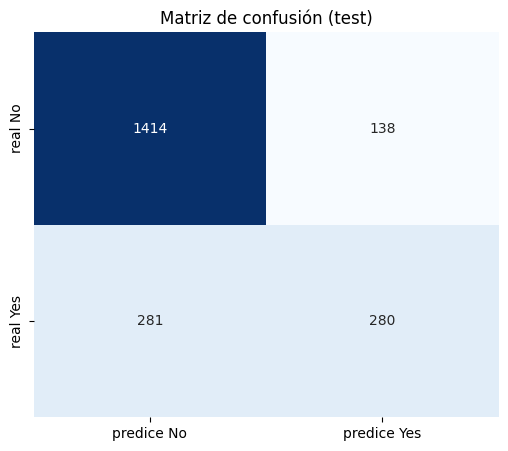

Verdaderos negativos: 1414 | Falsos positivos: 138
Falsos negativos: 281 | Verdaderos positivos: 280


In [39]:
matriz = confusion_matrix(y_test_t, pred_test_t)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['predice No', 'predice Yes'], yticklabels=['real No', 'real Yes'])
plt.title('Matriz de confusión (test)')
plt.show()

print('Verdaderos negativos:', matriz[0, 0], '| Falsos positivos:', matriz[0, 1])
print('Falsos negativos:', matriz[1, 0], '| Verdaderos positivos:', matriz[1, 1])

#### Conclusiones del reporte de clasificación
* El modelo generaliza bien. El AUC en test (**0,846**) es casi igual al de la validación cruzada (**0,848**), así que no hay sobreajuste.
* El accuracy es **80,2%**, por encima del 73,5% de predecir siempre No. Con clases desbalanceadas hay que mirar cada clase por separado.
* En la clase No (se queda) la precision es 0,83 y el recall 0,91. Reconoce bien a los que se quedan (1.414 de 1.552).
* En la clase Yes (se va) la precision es **0,67**. De cada 100 clientes que marca como baja, 67 se van de verdad (138 falsas alarmas). El recall es **0,50**, o sea que detecta **280** de las 561 bajas y se le escapan **281**. El F1 de esta clase es 0,57.
* El promedio macro del recall (0,705) es menor que el ponderado (0,80) porque el modelo funciona mejor con la clase mayoritaria. Es el efecto del desbalance.
* En retención suele costar más perder a un cliente que se iba (falso negativo) que ofrecerle un beneficio a uno que se iba a quedar (falso positivo). Con el umbral por defecto de 0,5 el modelo acierta bastante cuando marca a alguien, pero deja pasar la mitad de las bajas. Bajar ese umbral es una mejora posible para la etapa de optimización.

## A9. Entrenamiento con todos los datos disponibles

Ya validado y evaluado, entrenamos el modelo con todos los datos (train y test, **7.043** clientes). Usamos las mismas 10 variables de RFE y volvemos a ajustar Yeo-Johnson y la estandarización con todos los datos, en el mismo orden. Ya no quedan datos para evaluarlo, así que su rendimiento esperado es el que medimos en A8.

In [40]:
X_t_tr = X_t.copy()
yeo_final_t = PowerTransformer(method='yeo-johnson', standardize=False).fit(X_t[num_t])
X_t_tr[num_t] = yeo_final_t.transform(X_t[num_t])
escala_final_t = StandardScaler().fit(X_t_tr[num_t])
X_t_tr[num_t] = escala_final_t.transform(X_t_tr[num_t])

modelo_final_t = LogisticRegression(max_iter=1000)
modelo_final_t.fit(X_t_tr[sel_rfe_t], y_t)
print('Modelo final entrenado con', len(X_t_tr), 'clientes')

Modelo final entrenado con 7043 clientes


Como ejemplo de uso, le pedimos la probabilidad de baja de dos clientes inventados. Las columnas que no se indican quedan en 0, y a las numéricas se les aplican las mismas transformaciones.

In [41]:
nuevos = pd.DataFrame(0, index=['Cliente A', 'Cliente B'], columns=features_t)
nuevos.loc['Cliente A', ['tenure', 'MonthlyCharges', 'TotalCharges', 'PhoneService', 'PaperlessBilling', 'StreamingTV',
                         'InternetService_Fiber optic', 'PaymentMethod_Electronic check']] = [3, 95, 285, 1, 1, 1, 1, 1]
nuevos.loc['Cliente B', ['tenure', 'MonthlyCharges', 'TotalCharges', 'PhoneService', 'Partner', 'OnlineSecurity',
                         'TechSupport', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)']] = [48, 60, 2880, 1, 1, 1, 1, 1, 1]

nuevos[num_t] = yeo_final_t.transform(nuevos[num_t])
nuevos[num_t] = escala_final_t.transform(nuevos[num_t])

prediccion = modelo_final_t.predict(nuevos[sel_rfe_t])
probabilidades = modelo_final_t.predict_proba(nuevos[sel_rfe_t])
pd.DataFrame({'predicción': le_churn.inverse_transform(prediccion),
              'probabilidad de baja (%)': (probabilidades[:, 1] * 100).round(0).astype(int)}, index=nuevos.index)

,predicción,probabilidad de baja (%)
Cliente A,Yes,76
Cliente B,No,1


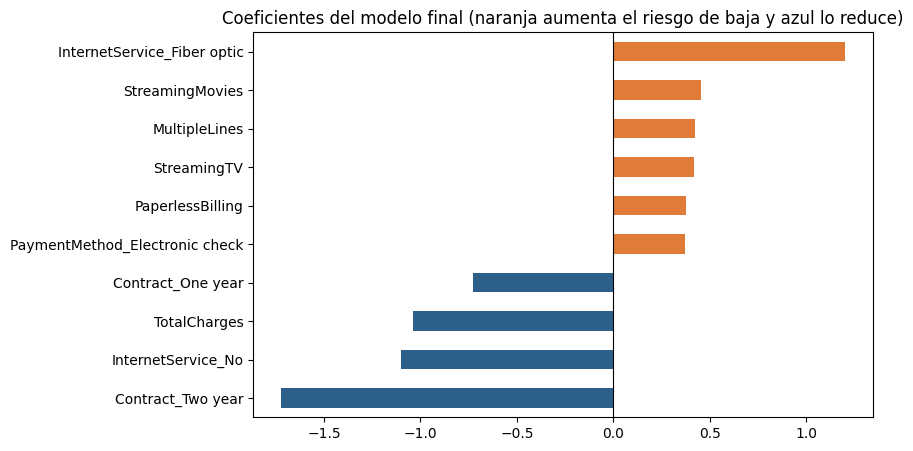

In [42]:
coeficientes_t = pd.Series(modelo_final_t.coef_[0], index=sel_rfe_t).sort_values()

colores = []
for valor in coeficientes_t:
    if valor > 0:
        colores.append(NARANJA)
    else:
        colores.append(AZUL)

coeficientes_t.plot(kind='barh', figsize=(8, 5), color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes del modelo final (naranja aumenta el riesgo de baja y azul lo reduce)')
plt.show()

* El cliente A (3 meses, fibra, contrato mes a mes y cheque electrónico) tiene **76%** de probabilidad de baja y el modelo predice que se va. El cliente B (4 años, DSL, contrato de 2 años y tarjeta) tiene **1%**.
* Lo que más reduce el riesgo es el contrato de 2 años (el coeficiente más grande), no tener internet (clientes que solo tienen teléfono), un total facturado alto (en la práctica, un cliente antiguo) y el contrato de 1 año.
* Lo que más lo aumenta es la fibra óptica, seguida del streaming, las líneas múltiples, la factura electrónica y el pago con cheque electrónico.

El perfil de mayor riesgo es el cliente nuevo con fibra, contrato mes a mes y cheque electrónico. Ofrecerle pasar a un contrato anual o adherirse al débito automático apunta justo a los factores que el modelo asocia con la permanencia.

# PARTE B. Regresión: Medical Cost Personal

## B1. Descripción del problema

El dataset tiene **1.338** personas con seguro médico en Estados Unidos. Proviene del libro Machine Learning with R de Brett Lantz y está publicado en Kaggle.

| Variable | Tipo | Descripción |
|---|---|---|
| age | numérica | Edad del titular (18 a 64 años) |
| sex | categórica (2) | female o male |
| bmi | numérica | Índice de masa corporal (peso sobre altura al cuadrado) |
| children | numérica | Hijos cubiertos por el seguro |
| smoker | categórica (2) | Si fuma, yes o no |
| region | categórica (4) | Región de Estados Unidos (northeast, northwest, southeast, southwest) |
| **charges** | numérica | Costo médico anual facturado al seguro, en dólares. Es la variable objetivo |

El objetivo es predecir el costo médico anual de una persona a partir de sus características. Es un problema de regresión porque la respuesta es un número. A una aseguradora le sirve para fijar primas y entender qué factores pesan más en el costo.

#### Por qué elegimos este dataset
* Mezcla variables numéricas y categóricas, así que hay que codificar.
* La variable objetivo es muy asimétrica y tiene valores atípicos reales.
* Tiene un duplicado para limpiar.
* Hay una relación no lineal (el efecto del IMC depende de si la persona fuma), un buen caso para comparar modelos lineales y no lineales.

## B2. Análisis exploratorio de datos (EDA)

### B2.1 Dimensiones y tipos de datos

In [43]:
df_i = pd.read_csv('insurance.csv')
print('Dimensiones:', df_i.shape)
df_i.head()

Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.924
1,18,male,33.770,1,no,southeast,1725.552
2,28,male,33.000,3,no,southeast,4449.462
3,33,male,22.705,0,no,northwest,21984.471
4,32,male,28.880,0,no,northwest,3866.855


In [44]:
df_i.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


No hay valores faltantes y los tipos de datos son correctos. **age**, **bmi**, **children** y **charges** son numéricas, y **sex**, **smoker** y **region** son texto.

### B2.2 Estadística descriptiva

In [45]:
num_i = ['age', 'bmi', 'children']
cat_i = ['sex', 'smoker', 'region']

resumen_i = df_i.describe().T
resumen_i['mediana'] = df_i[num_i + ['charges']].median()
resumen_i

,count,mean,std,min,25%,50%,75%,max,mediana
age,1338.0,39.207,14.050,18.000,27.000,39.000,51.000,64.000,39.000
bmi,1338.0,30.663,6.098,15.960,26.296,30.400,34.694,53.130,30.400
children,1338.0,1.095,1.205,0.000,0.000,1.000,2.000,5.000,1.000
charges,1338.0,13270.422,12110.011,1121.874,4740.287,9382.033,16639.913,63770.428,9382.033


In [46]:
df_i[cat_i].describe().T

,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


* **age** va de 18 a 64 años y **bmi** de 16 a 53, con una mediana de 30,4.
* En **charges** la media (**13.270** dólares) es mucho mayor que la mediana (**9.382**). Muchas personas tienen costos bajos y pocas tienen costos muy altos.
* **children** va de 0 a 5 y la mitad tiene como mucho 1 hijo.

### B2.3 Distribución de las categorías y costo por grupo

En regresión no hay clases, pero conviene ver cómo se reparten las categorías y cuánto cuesta cada grupo.

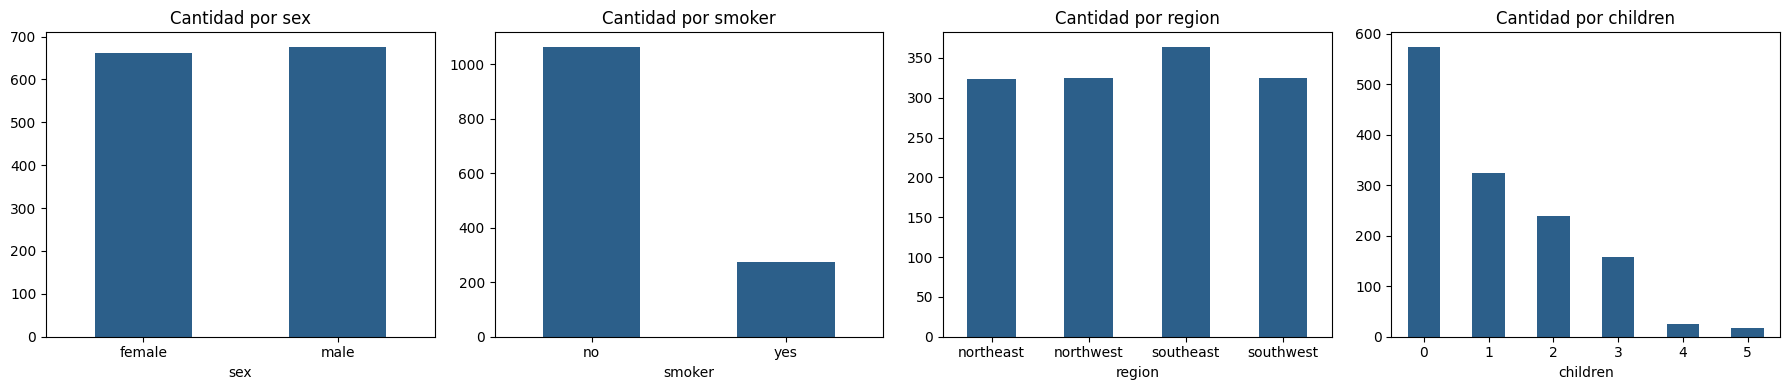

        count     mean     50%
sex                           
female  662.0  12570.0  9413.0
male    676.0  13957.0  9370.0

         count     mean      50%
smoker                          
no      1064.0   8434.0   7345.0
yes      274.0  32050.0  34456.0

           count     mean      50%
region                            
northeast  324.0  13406.0  10058.0
northwest  325.0  12418.0   8966.0
southeast  364.0  14735.0   9294.0
southwest  325.0  12347.0   8799.0



In [47]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(cat_i + ['children']):
    df_i[col].value_counts().sort_index().plot(kind='bar', ax=axs[i], color=AZUL, rot=0)
    axs[i].set_title('Cantidad por ' + col)
plt.tight_layout()
plt.show()

for col in cat_i:
    print(df_i.groupby(col)['charges'].describe()[['count', 'mean', '50%']].round(0))
    print()

* **sex** y **region** están balanceadas, con cerca de 50% y 25% por categoría.
* Solo el **20%** fuma, pero su costo medio (**32.050** dólares) es casi 4 veces el de los que no fuman (**8.434**). Es la diferencia más grande del dataset.
* Entre sexos y entre regiones las diferencias de costo son mucho más chicas.

### B2.4 Asimetría

In [48]:
df_i[num_i + ['charges']].skew()

age         0.056
bmi         0.284
children    0.938
charges     1.516
dtype: float64

**charges** tiene asimetría fuerte (**1,52**). **children** es moderada (0,94) porque es un conteo con muchos ceros, y **age** y **bmi** son casi simétricas.

### B2.5 Histogramas y gráficos de densidad

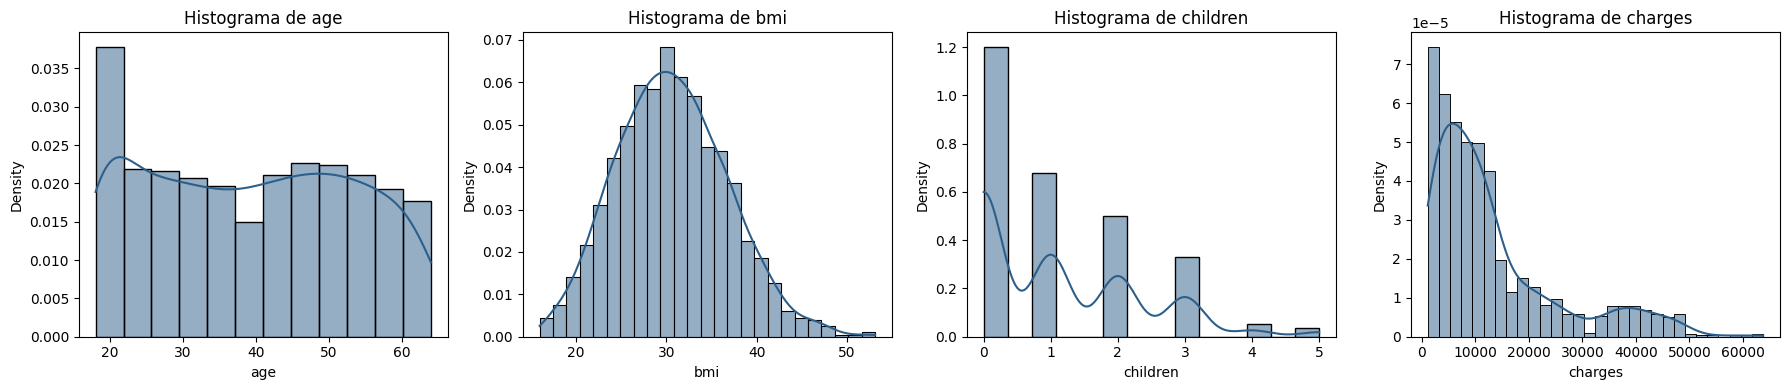

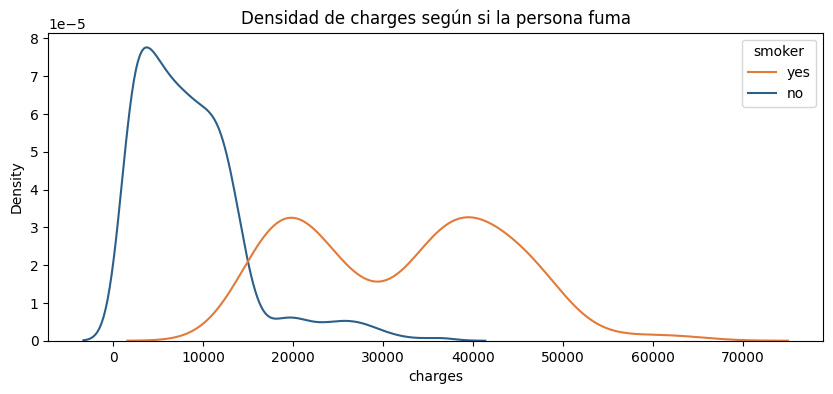

In [49]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(num_i + ['charges']):
    sns.histplot(df_i[col], ax=axs[i], stat='density', kde=True, color=AZUL)
    axs[i].set_title('Histograma de ' + col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.kdeplot(data=df_i, x='charges', hue='smoker', common_norm=False, palette={'no': AZUL, 'yes': NARANJA})
plt.title('Densidad de charges según si la persona fuma')
plt.show()

El histograma de **charges** es asimétrico y tiene varios picos. La densidad por **smoker** explica por qué. Los que no fuman se concentran en costos bajos y los que fuman forman dos grupos, uno cerca de 20.000 dólares y otro cerca de 40.000. El costo mezcla grupos de personas distintos, algo que un modelo lineal no capta solo.

### B2.6 Boxplots

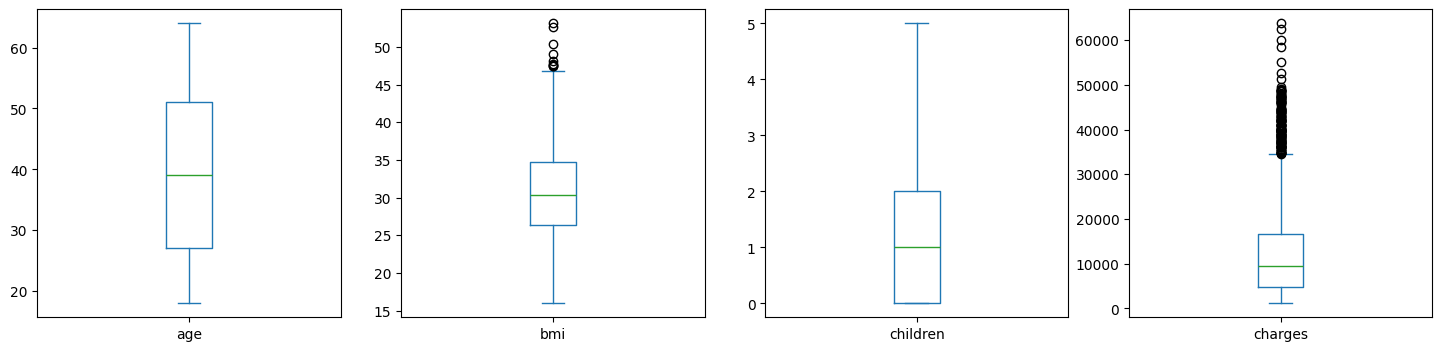

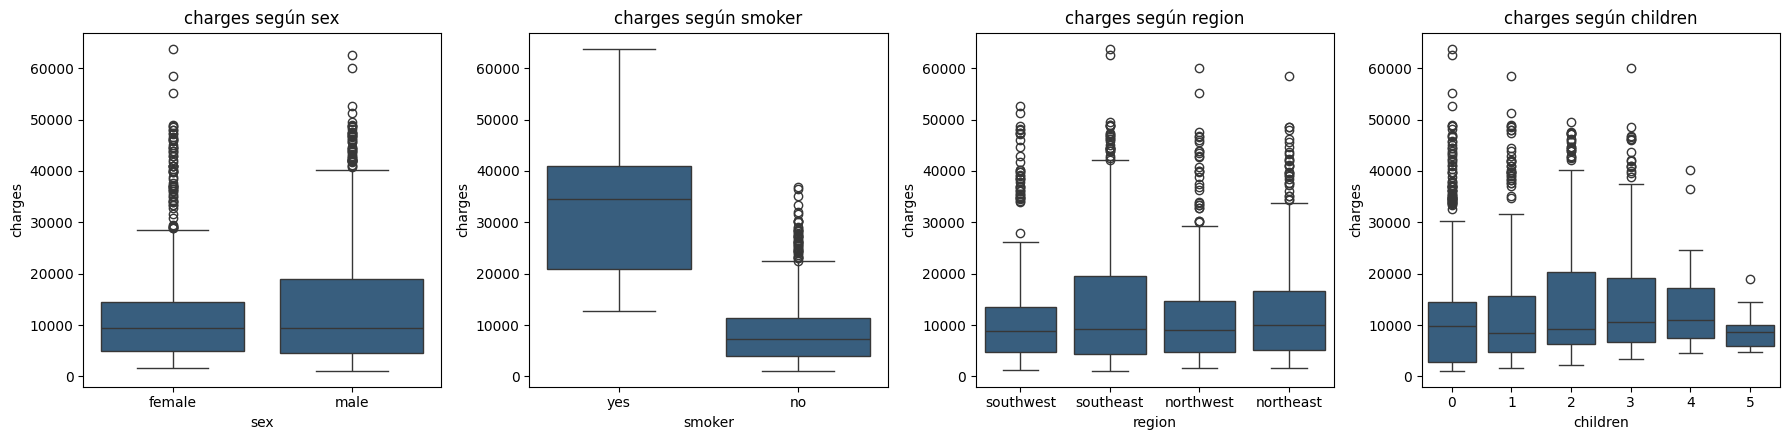

In [50]:
df_i[num_i + ['charges']].plot(kind='box', subplots=True, layout=(1, 4), figsize=(18, 4), sharex=False)
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))
for i, col in enumerate(cat_i + ['children']):
    sns.boxplot(df_i, x=col, y='charges', ax=axs[i], color=AZUL)
    axs[i].set_title('charges según ' + col)
plt.tight_layout()
plt.show()

* En el boxplot de **charges** hay muchos puntos por encima del bigote. Son los costos altos, casi todos de fumadores.
* **bmi** tiene unos pocos atípicos por encima de 47.
* La caja de los fumadores está completamente por encima de la de los que no fuman. Por sexo, región y cantidad de hijos las cajas son parecidas.

### B2.7 Matriz de correlación

Igual que en la parte A, en una copia pasamos **sex** y **smoker** a 0 y 1 y **region** a variables dummy. La codificación definitiva va en B3.

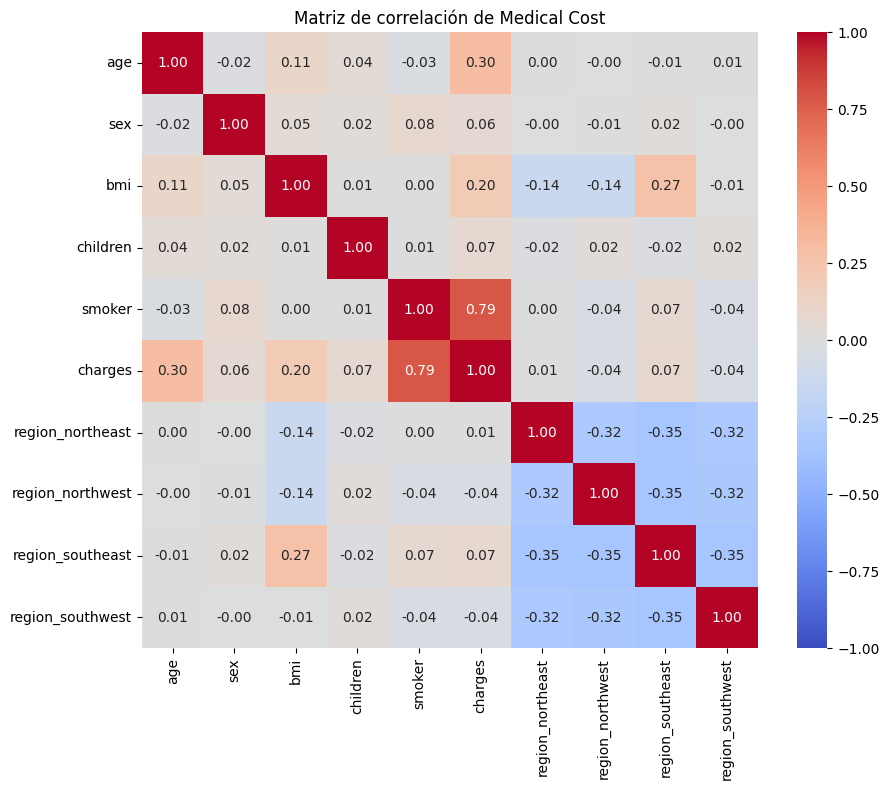

region_southwest   -0.043
region_northwest   -0.040
region_northeast    0.006
sex                 0.057
children            0.068
region_southeast    0.074
bmi                 0.198
age                 0.299
smoker              0.787
Name: charges, dtype: float64

In [51]:
df_i_corr = df_i.copy()
df_i_corr['sex'] = (df_i_corr['sex'] == 'male').astype(int)
df_i_corr['smoker'] = (df_i_corr['smoker'] == 'yes').astype(int)
df_i_corr = pd.get_dummies(df_i_corr, columns=['region'], dtype=int)
correlacion_i = df_i_corr.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacion_i, vmin=-1, vmax=1, cmap='coolwarm', annot=True, fmt='.2f', square=True)
plt.title('Matriz de correlación de Medical Cost')
plt.show()

correlacion_i['charges'].drop('charges').sort_values()

* **smoker** es la variable más correlacionada con el costo (**0,79**), muy lejos de las demás.
* Después vienen **age** (0,30) y **bmi** (0,20). **children**, **sex** y la región casi no se relacionan con el costo.
* Entre las variables de entrada no hay correlaciones altas, así que no hay variables redundantes.

### B2.8 Matriz de dispersión

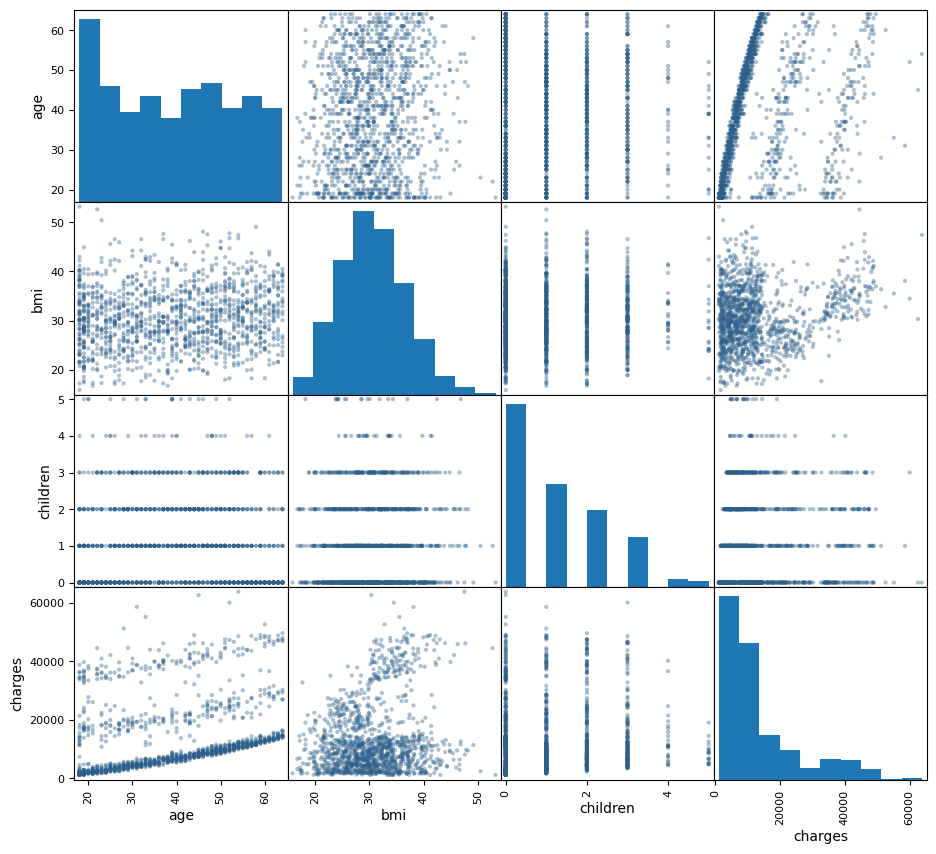

In [52]:
pd.plotting.scatter_matrix(df_i[num_i + ['charges']], figsize=(11, 10), alpha=0.4, color=AZUL)
plt.show()

La matriz muestra que **charges** sube con **age**, pero en bandas separadas. Para ver qué forma esas bandas repetimos la dispersión de **age** y **bmi** contra **charges** separando por **smoker**.

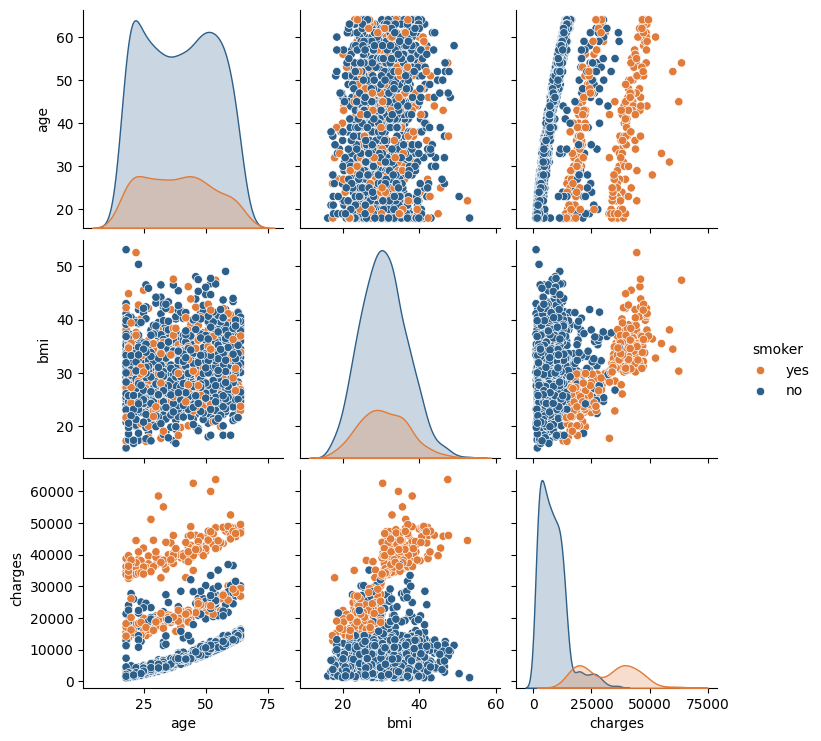

In [53]:
sns.pairplot(df_i[['age', 'bmi', 'charges', 'smoker']], hue='smoker', palette={'no': AZUL, 'yes': NARANJA})
plt.show()

Este es el hallazgo más importante del EDA.
* En **charges** contra **age** aparecen tres bandas paralelas. En todas el costo sube con la edad, pero los que no fuman están abajo y los que fuman en dos niveles.
* En **charges** contra **bmi**, para los que no fuman el IMC casi no influye. En los fumadores hay un salto en IMC 30, el corte de obesidad. Con obesidad cuestan cerca de 40.000 dólares y sin obesidad cerca de 20.000.

El efecto del IMC depende de si la persona fuma. Lo aprovechamos en B3.2 creando una variable nueva.

### B2.9 Valores faltantes, duplicados, atípicos e inconsistencias

In [54]:
print('Faltantes:', df_i.isna().sum().sum())
print('Filas duplicadas:', df_i.duplicated().sum())
print(df_i[df_i.duplicated(keep=False)])

print('\nCategorías de cada variable')
for col in cat_i:
    print(col, list(df_i[col].unique()))

columnas_num = num_i + ['charges']
q1 = df_i[columnas_num].quantile(0.25)
q3 = df_i[columnas_num].quantile(0.75)
iqr = q3 - q1
fuera = (df_i[columnas_num] < q1 - 1.5 * iqr) | (df_i[columnas_num] > q3 + 1.5 * iqr)
print('\nValores atípicos según el rango intercuartílico')
print(fuera.sum())
print(f"\n% de fumadores entre los atípicos de charges: {(df_i[fuera['charges']]['smoker'] == 'yes').mean() * 100:.0f}%")

Faltantes: 0
Filas duplicadas: 1
     age   sex    bmi  children smoker     region   charges
195   19  male  30.59         0     no  northwest  1639.563
581   19  male  30.59         0     no  northwest  1639.563

Categorías de cada variable
sex ['female', 'male']
smoker ['yes', 'no']
region ['southwest', 'southeast', 'northwest', 'northeast']

Valores atípicos según el rango intercuartílico
age           0
bmi           9
children      0
charges     139
dtype: int64

% de fumadores entre los atípicos de charges: 98%


#### Decisión
1. No hay faltantes. Las categorías están bien escritas y los tipos de datos son correctos.
2. Hay **1** fila repetida con el mismo costo hasta el último decimal. Es muy poco probable que sean dos personas distintas, así que la tomamos como un error de carga y la eliminamos.
3. **charges** tiene **139** valores altos según el rango intercuartílico (**10,4%**) y el **98%** son de fumadores. Los conservamos porque no son errores. Son los pacientes caros, los más importantes para una aseguradora. Los 9 atípicos de **bmi** (hasta 53) son valores posibles, así que también quedan.

In [55]:
df_i = df_i.drop_duplicates().reset_index(drop=True)
print('Filas después de eliminar el duplicado:', len(df_i))

Filas después de eliminar el duplicado: 1337


## B3. Preprocesamiento de datos

### B3.1 Codificación de variables categóricas

| Variable | Técnica | Motivo |
|---|---|---|
| sex | Label Encoding | Binaria, female pasa a 0 y male a 1 |
| smoker | Label Encoding | Binaria, no pasa a 0 y yes a 1 |
| region | One-Hot Encoding con drop_first=True | 4 categorías sin orden. Con 0 a 3 el modelo supondría que una región es mayor que otra |

Como en la parte A, no usamos Target Encoding porque region tiene solo 4 categorías. Estas codificaciones no usan **charges**, así que se pueden aplicar antes de separar train y test.

In [56]:
df_i_cod = df_i.copy()
le_sex = LabelEncoder()
le_smoker = LabelEncoder()
df_i_cod['sex'] = le_sex.fit_transform(df_i_cod['sex'])
df_i_cod['smoker'] = le_smoker.fit_transform(df_i_cod['smoker'])
df_i_cod = pd.get_dummies(df_i_cod, columns=['region'], drop_first=True, dtype=int)

print('sex:', le_sex.classes_, 'pasan a', le_sex.transform(le_sex.classes_))
print('smoker:', le_smoker.classes_, 'pasan a', le_smoker.transform(le_smoker.classes_))

sex: ['female' 'male'] pasan a [0 1]
smoker: ['no' 'yes'] pasan a [0 1]


In [57]:
# Antes de codificar
df_i.head(3)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.924
1,18,male,33.77,1,no,southeast,1725.552
2,28,male,33.00,3,no,southeast,4449.462


In [58]:
# Después de codificar
df_i_cod.head(3)

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.90,0,1,16884.924,0,0,1
1,18,1,33.77,1,0,1725.552,0,1,0
2,28,1,33.00,3,0,4449.462,0,1,0


### B3.2 Binarización del IMC y variable nueva

El EDA mostró que el costo salta en los fumadores cuando el IMC pasa de 30. Lo representamos con dos variables.
* **obeso**, la binarización de **bmi** con umbral 30 (Binarizer), el corte de obesidad de la OMS.
* **fumador_obeso**, que es **smoker** por **obeso**. Vale 1 solo si la persona fuma y tiene obesidad.

Un modelo lineal suma los efectos de cada variable por separado, así que no puede captar solo que el IMC pese distinto en los fumadores. Si le damos esa variable, sí. Como el umbral es fijo y no se aprende de los datos, se puede crear antes de separar train y test sin filtrar información.

Desde acá el modelo base son **10** variables, las 8 originales codificadas más estas 2.

In [59]:
binarizador = Binarizer(threshold=30)
df_i_cod['obeso'] = binarizador.fit_transform(df_i_cod[['bmi']])[:, 0].astype(int)
df_i_cod['fumador_obeso'] = df_i_cod['smoker'] * df_i_cod['obeso']

# Antes (bmi continuo) y después (binarización e interacción)
df_i_cod[['bmi', 'obeso', 'smoker', 'fumador_obeso']].head(6)

,bmi,obeso,smoker,fumador_obeso
0,27.900,0,1,0
1,33.770,1,0,0
2,33.000,1,0,0
3,22.705,0,0,0
4,28.880,0,0,0
5,25.740,0,0,0


smoker  obeso
0       0         7967.0
        1         8866.0
1       0        21369.0
        1        41693.0
Name: charges, dtype: float64


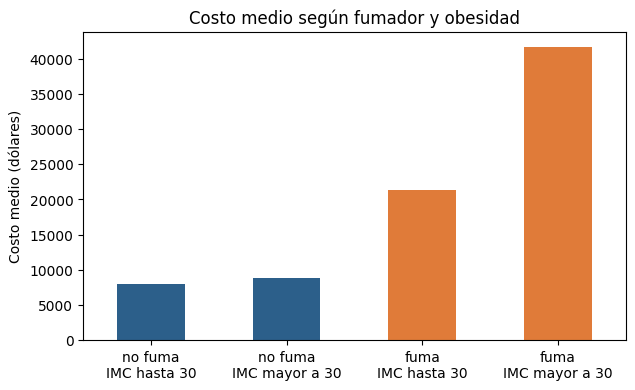

In [60]:
costo_grupo = df_i_cod.groupby(['smoker', 'obeso'])['charges'].mean()
print(costo_grupo.round(0))

costo_grupo.index = ['no fuma\nIMC hasta 30', 'no fuma\nIMC mayor a 30', 'fuma\nIMC hasta 30', 'fuma\nIMC mayor a 30']
costo_grupo.plot(kind='bar', color=[AZUL, AZUL, NARANJA, NARANJA], rot=0, figsize=(7, 4))
plt.xlabel('')
plt.ylabel('Costo medio (dólares)')
plt.title('Costo medio según fumador y obesidad')
plt.show()

Entre los que no fuman la obesidad casi no cambia el costo (**7.967** contra **8.866** dólares). Entre los que fuman lo duplica (**21.369** contra **41.693**).

### B3.3 División en entrenamiento y prueba

Separamos 70% para train y 30% para test. Estratificamos por **smoker** para que las dos partes tengan la misma proporción de fumadores, porque es la variable que más mueve el costo.

In [61]:
X_i = df_i_cod.drop(columns='charges')
y_i = df_i_cod['charges']
features_i = X_i.columns.tolist()

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_i, y_i, test_size=0.3,
                                                            random_state=SEMILLA, stratify=X_i['smoker'])
print('Train:', X_train_i.shape, 'Test:', X_test_i.shape)
print(f'Costo medio en train: {y_train_i.mean():.0f} y en test: {y_test_i.mean():.0f} dólares')
print(f"% de fumadores en train: {X_train_i['smoker'].mean() * 100:.1f}% y en test: {X_test_i['smoker'].mean() * 100:.1f}%")
print('Variables del modelo base:', features_i)

Train: (935, 10) Test: (402, 10)


Costo medio en train: 13298 y en test: 13236 dólares
% de fumadores en train: 20.5% y en test: 20.4%
Variables del modelo base: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'obeso', 'fumador_obeso']


### B3.4 Estandarización de las variables numéricas de entrada

**age**, **bmi** y **children** están en escalas distintas. Las estandarizamos (media 0 y desvío 1) porque KNN mide distancias y PCA busca la mayor varianza, así que sin este paso **age** pesaría más que **children** solo por su escala. El ajuste se hace solo con train y las variables 0 y 1 no se transforman.

No transformamos **charges** aunque sea asimétrica. La consigna pide el mismo scoring para todos los modelos y la evaluación final en la misma métrica. Si un modelo aprendiera sobre **charges** transformada, su error quedaría en otra escala y no se podría comparar en dólares con los demás.

In [62]:
escala_i = StandardScaler().fit(X_train_i[num_i])
X_train_i_tr = X_train_i.copy()
X_test_i_tr = X_test_i.copy()
X_train_i_tr[num_i] = escala_i.transform(X_train_i[num_i])
X_test_i_tr[num_i] = escala_i.transform(X_test_i[num_i])

In [63]:
# Antes (train)
X_train_i[num_i].describe().loc[['mean', 'std', 'min', 'max']]

,age,bmi,children
mean,39.066,30.818,1.084
std,14.098,6.100,1.177
min,18.000,16.815,0.000
max,64.000,53.130,5.000


In [64]:
# Después (train)
X_train_i_tr[num_i].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,age,bmi,children
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.50,-2.30,-0.92
max,1.77,3.66,3.33


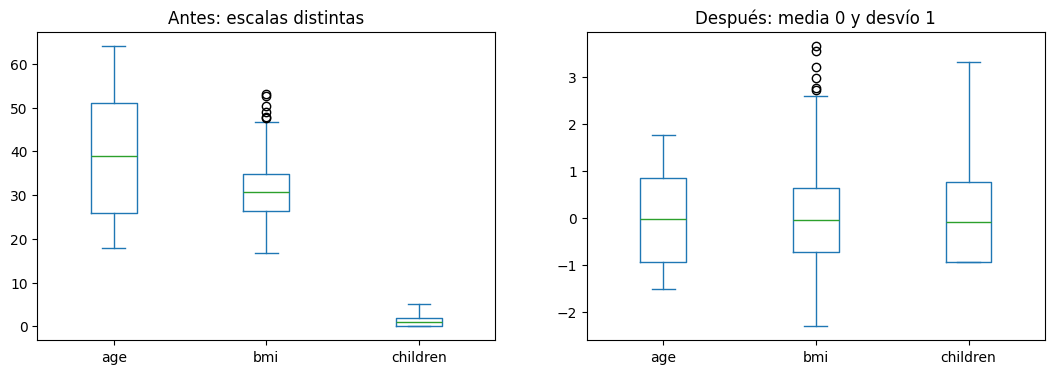

In [65]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
X_train_i[num_i].plot(kind='box', ax=axs[0], title='Antes: escalas distintas')
X_train_i_tr[num_i].plot(kind='box', ax=axs[1], title='Después: media 0 y desvío 1')
plt.show()

## B4. Selección de características y reducción de dimensiones

Para regresión aplicamos **Feature Importance con Random Forest**, una técnica distinta de la de clasificación (RFE), y **PCA** sobre las 10 variables del modelo base, por separado de la selección.

### B4.1 Feature Importance con Random Forest

Un Random Forest entrena muchos árboles. Cada vez que un árbol usa una variable para hacer un corte, el error baja, y la importancia de la variable es cuánto baja el error en promedio en todos esos cortes. Las importancias suman 1.

La elegimos porque los árboles captan relaciones no lineales como la de fumar con obesidad, algo que una correlación de a una variable no mide. Además no necesitan variables estandarizadas, así que la ajustamos sobre train sin transformar. Conservamos las variables con importancia de al menos **1%**.

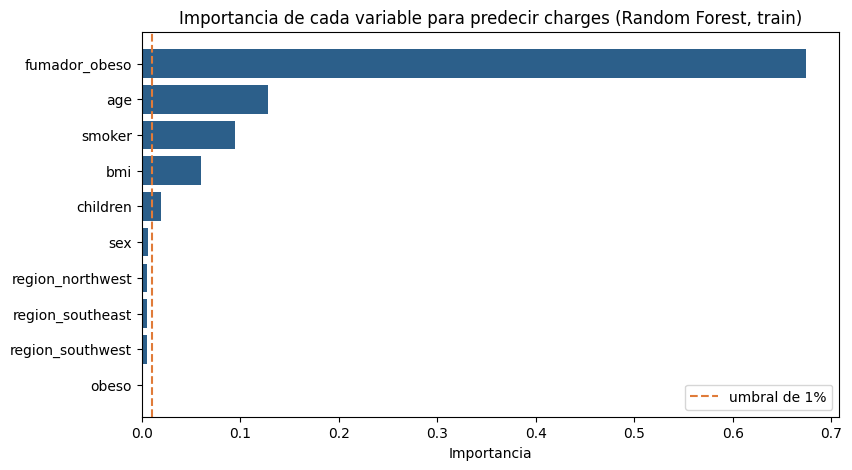

Variables seleccionadas: ['fumador_obeso', 'age', 'smoker', 'bmi', 'children']


fumador_obeso       0.674
age                 0.128
smoker              0.095
bmi                 0.060
children            0.019
sex                 0.006
region_northwest    0.005
region_southeast    0.005
region_southwest    0.005
obeso               0.002
dtype: float64

In [66]:
bosque = RandomForestRegressor(random_state=SEMILLA)
bosque.fit(X_train_i, y_train_i)

importancias = pd.Series(bosque.feature_importances_, index=features_i).sort_values()
sel_rf_i = importancias[importancias >= 0.01].sort_values(ascending=False).index.tolist()

plt.figure(figsize=(9, 5))
plt.barh(range(len(importancias)), importancias, color=AZUL)
plt.yticks(range(len(importancias)), importancias.index)
plt.axvline(0.01, color=NARANJA, linestyle='--', label='umbral de 1%')
plt.xlabel('Importancia')
plt.title('Importancia de cada variable para predecir charges (Random Forest, train)')
plt.legend()
plt.show()

print('Variables seleccionadas:', sel_rf_i)
importancias.sort_values(ascending=False).round(3)

* **fumador_obeso** concentra el **67%** de la importancia, seguida por **age** (13%) y **smoker** (9,5%).
* Con el umbral de 1% quedan **5** variables, que son **fumador_obeso**, **age**, **smoker**, **bmi** y **children**.
* Quedan afuera **sex** y las regiones, que el EDA ya mostraba como poco relevantes, y también **obeso**, porque su información ya está en **bmi** y en **fumador_obeso**.

### B4.2 Reducción de dimensiones con PCA

Aplicamos PCA sobre las **10** variables del modelo base y no sobre las seleccionadas por Random Forest. Como en la parte A, antes estandarizamos todas las variables. Si no, **smoker** y **fumador_obeso**, que son 0 y 1 y tienen poca varianza, casi no pesarían en las componentes aunque sean las que más explican el costo. Conservamos las componentes que explican el 90% de la varianza.

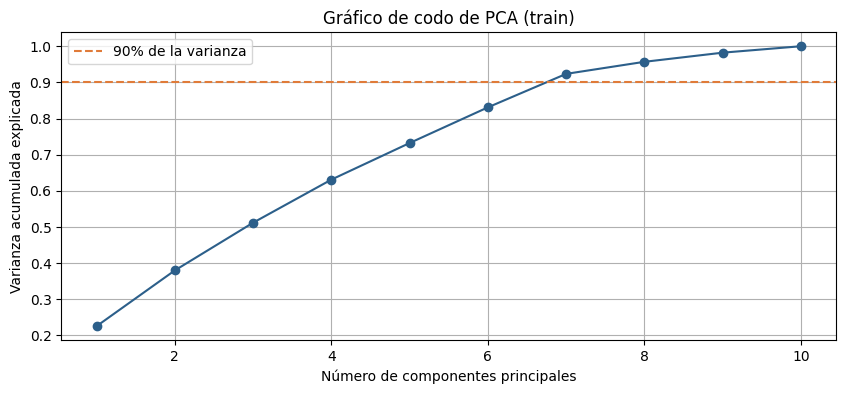

Varianza acumulada: [0.225 0.38  0.512 0.631 0.732 0.831 0.924 0.957 0.982 1.   ]
Componentes para el 90%: 7 de 10


In [67]:
escala_pca_i = StandardScaler().fit(X_train_i_tr)
X_train_i_esc = escala_pca_i.transform(X_train_i_tr)
X_test_i_esc = escala_pca_i.transform(X_test_i_tr)

pca_todas_i = PCA().fit(X_train_i_esc)
varianza_acumulada_i = np.cumsum(pca_todas_i.explained_variance_ratio_)
n_pca_i = (varianza_acumulada_i < 0.90).sum() + 1

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(varianza_acumulada_i) + 1), varianza_acumulada_i, marker='o', color=AZUL)
plt.axhline(y=0.9, color=NARANJA, linestyle='--', label='90% de la varianza')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza acumulada explicada')
plt.title('Gráfico de codo de PCA (train)')
plt.legend()
plt.grid(True)
plt.show()

print('Varianza acumulada:', varianza_acumulada_i.round(3))
print(f'Componentes para el 90%: {n_pca_i} de {len(features_i)}')

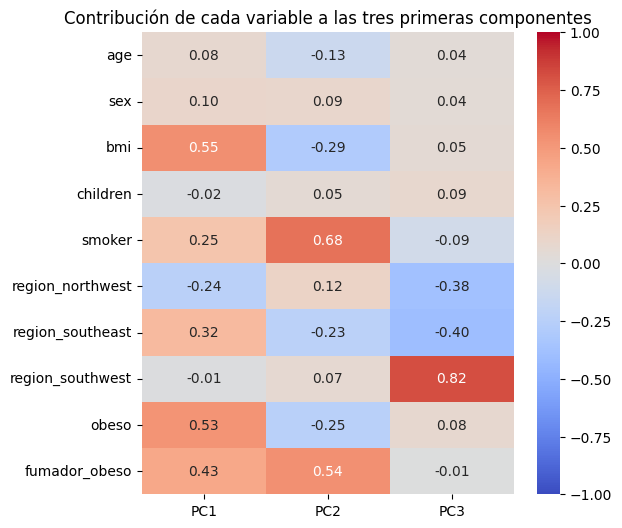

In [68]:
pca_i = PCA(n_components=n_pca_i).fit(X_train_i_esc)
X_train_i_pca = pca_i.transform(X_train_i_esc)
X_test_i_pca = pca_i.transform(X_test_i_esc)

plt.figure(figsize=(6, 6))
sns.heatmap(pca_i.components_[:3].T, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f',
            xticklabels=['PC1', 'PC2', 'PC3'], yticklabels=features_i)
plt.title('Contribución de cada variable a las tres primeras componentes')
plt.show()

* Hacen falta **7** de 10 componentes para llegar al 90% de la varianza. La reducción es chica porque las variables están poco correlacionadas entre sí y cada una aporta información propia.
* La PC1 (**22%**) junta **bmi**, **obeso** y **fumador_obeso**, así que representa la obesidad. La PC2 junta **smoker** y **fumador_obeso** y representa fumar. La PC3 contrapone las regiones.
* Como en la parte A, cada componente mezcla varias variables y se pierde la interpretación directa.

## B5. Entrenamiento y comparación de modelos

Comparamos **LinearRegression** (taxonomía lineal) con un modelo no lineal, cada uno con tres conjuntos de variables.

| Conjunto | Qué recibe el modelo |
|---|---|
| Base | Las 10 variables (numéricas estandarizadas) |
| Random Forest | Las 5 variables con importancia de al menos 1% |
| PCA | Las 7 componentes calculadas sobre las 10 variables del modelo base |

Los 6 modelos se comparan con K-Fold de 10 particiones sobre train y el mismo scoring, **neg_mean_squared_error**. Scikit-learn devuelve el error en negativo porque siempre busca el valor más alto, así que cuanto más cerca de 0, mejor. Para leerlo en dólares mostramos también su raíz, el RMSE. Elegimos el MSE porque castiga más los errores grandes, y para una aseguradora equivocarse por mucho en un cliente caro es lo más costoso.

### B5.1 Elección del modelo no lineal

Probamos los regresores no lineales de la clase de Algoritmos de ML con su configuración por defecto, sobre el modelo base.

In [69]:
no_lineales_i = {'KNN': KNeighborsRegressor(),
                 'Árbol de decisión': DecisionTreeRegressor(random_state=SEMILLA),
                 'SVR': SVR()}

for nombre, modelo in no_lineales_i.items():
    resultados = cross_val_score(modelo, X_train_i_tr, y_train_i, cv=kfold, scoring='neg_mean_squared_error')
    print(f'{nombre}: Neg MSE {resultados.mean():.0f} | RMSE {np.sqrt(abs(resultados.mean())):.0f} dólares')

KNN: Neg MSE -30732771 | RMSE 5544 dólares
Árbol de decisión: Neg MSE -45797686 | RMSE 6767 dólares


SVR: Neg MSE -164014842 | RMSE 12807 dólares


#### Decisión
Elegimos **KNN** (KNeighborsRegressor) como modelo no lineal.
* Es el no lineal con menor error (RMSE de **5.544** dólares), contra 6.767 del árbol sin límite de profundidad, que se sobreajusta.
* SVR con sus valores por defecto da un RMSE de 12.807 dólares, casi lo mismo que predecir siempre el promedio. Sus valores por defecto están pensados para una variable objetivo en escala chica, y **charges** está en miles de dólares.
* KNN predice promediando el costo de las 5 personas más parecidas, sin suponer una relación lineal. Es un enfoque muy distinto al de la regresión lineal.

### B5.2 Comparación de los 6 modelos

In [70]:
conjuntos_i = {f'Base ({len(features_i)} var.)': (X_train_i_tr, X_test_i_tr),
               f'Random Forest ({len(sel_rf_i)} var.)': (X_train_i_tr[sel_rf_i], X_test_i_tr[sel_rf_i]),
               f'PCA ({n_pca_i} comp.)': (X_train_i_pca, X_test_i_pca)}
modelos_i = {'LinearRegression': LinearRegression(),
             'KNN': KNeighborsRegressor()}

folds_i = {}
filas = []
for nombre_conj, (X_train_conj, X_test_conj) in conjuntos_i.items():
    for nombre_mod, modelo in modelos_i.items():
        resultados = cross_val_score(modelo, X_train_conj, y_train_i, cv=kfold, scoring='neg_mean_squared_error')
        folds_i[nombre_mod + '\n' + nombre_conj] = np.sqrt(-resultados)
        filas.append([nombre_mod, nombre_conj, resultados.mean(), np.sqrt(-resultados.mean()), np.sqrt(-resultados).std()])

tabla_i = pd.DataFrame(filas, columns=['modelo', 'conjunto', 'Neg MSE medio', 'RMSE (dólares)', 'desvío del RMSE'])
tabla_i['Neg MSE medio'] = tabla_i['Neg MSE medio'].astype(int)
tabla_i.round(0)

,modelo,conjunto,Neg MSE medio,RMSE (dólares),desvío del RMSE
0,LinearRegression,Base (10 var.),-20762418,4557.0,884.0
1,KNN,Base (10 var.),-30732770,5544.0,644.0
2,LinearRegression,Random Forest (5 var.),-20805343,4561.0,889.0
3,KNN,Random Forest (5 var.),-26418595,5140.0,656.0
4,LinearRegression,PCA (7 comp.),-20930771,4575.0,843.0
5,KNN,PCA (7 comp.),-26558183,5153.0,810.0


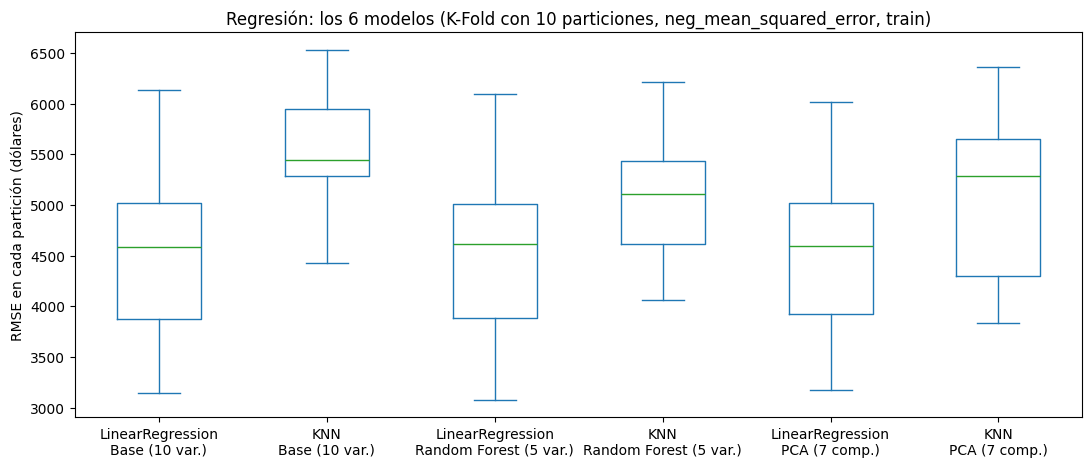

In [71]:
pd.DataFrame(folds_i).plot(kind='box', figsize=(13, 5))
plt.ylabel('RMSE en cada partición (dólares)')
plt.title('Regresión: los 6 modelos (K-Fold con 10 particiones, neg_mean_squared_error, train)')
plt.show()

* La regresión lineal es la mejor con los tres conjuntos (**4.557**, **4.561** y **4.575** dólares de RMSE), por delante de KNN (5.544, 5.140 y 5.153).
* Gana el modelo lineal porque los tres conjuntos tienen **fumador_obeso**. El salto del costo que encontramos en el EDA ya está representado como una variable, así que la regresión lineal no necesita descubrirlo por su cuenta.
* Para la regresión lineal el modelo base y la selección con Random Forest empatan. La diferencia es de 4 dólares contra un desvío entre particiones de casi 900, y la selección usa **5** variables en lugar de 10.
* PCA da casi lo mismo con la regresión lineal usando 7 componentes, pero se pierde la interpretación. A KNN la selección y PCA lo ayudan un poco porque le sacan variables sin información que distorsionan las distancias, aunque sigue por detrás.

## B6. Optimización de hiperparámetros y selección del mejor modelo

Según la consigna, acá iría la optimización de hiperparámetros, que no se realiza en este TP.

#### Decisión
Elegimos **LinearRegression con las 5 variables de Random Forest**.
1. Empata con el mejor modelo (la regresión lineal con las 10 variables). La diferencia de 4 dólares no es relevante frente a la variación entre particiones.
2. Usa **5** variables en lugar de 10, la mitad de los datos para recolectar.
3. Sus coeficientes se leen en dólares, por ejemplo cuánto suma fumar por año. Para una aseguradora eso sirve para explicar y justificar una prima. KNN no da esa explicación.
4. Es el modelo más rápido de entrenar.

## B7. Entrenamiento con el conjunto de entrenamiento completo

Entrenamos el modelo elegido con todo train (**935** personas).

In [72]:
modelo_i = LinearRegression()
modelo_i.fit(X_train_i_tr[sel_rf_i], y_train_i)
print('Entrenado con', len(X_train_i_tr), 'personas y', len(sel_rf_i), 'variables')

Entrenado con 935 personas y 5 variables


## B8. Evaluación final del modelo

Evaluamos con el conjunto de test (**402** personas que no se usaron antes) con la misma métrica que en B5, el MSE. Como complemento mostramos el RMSE, el MAE y el R², y comparamos con predecir siempre el costo promedio de train.

In [73]:
pred_test_i = modelo_i.predict(X_test_i_tr[sel_rf_i])
mse_test = mean_squared_error(y_test_i, pred_test_i)
fila_elegida = (tabla_i['modelo'] == 'LinearRegression') & (tabla_i['conjunto'] == f'Random Forest ({len(sel_rf_i)} var.)')
neg_mse_cv = tabla_i[fila_elegida]['Neg MSE medio'].iloc[0]
mse_promedio = mean_squared_error(y_test_i, np.ones(len(y_test_i)) * y_train_i.mean())

print(f'Neg MSE en test: {-mse_test:.0f} | RMSE: {np.sqrt(mse_test):.0f} dólares')
print(f'Neg MSE en validación cruzada: {neg_mse_cv:.0f} | RMSE: {np.sqrt(-neg_mse_cv):.0f} dólares')
print(f'Predecir siempre el promedio: {-mse_promedio:.0f} | RMSE: {np.sqrt(mse_promedio):.0f} dólares')
print(f'\nMAE: {mean_absolute_error(y_test_i, pred_test_i):.0f} dólares | R²: {r2_score(y_test_i, pred_test_i):.3f}')

Neg MSE en test: -18784555 | RMSE: 4334 dólares
Neg MSE en validación cruzada: -20805343 | RMSE: 4561 dólares
Predecir siempre el promedio: -142110692 | RMSE: 11921 dólares

MAE: 2434 dólares | R²: 0.868


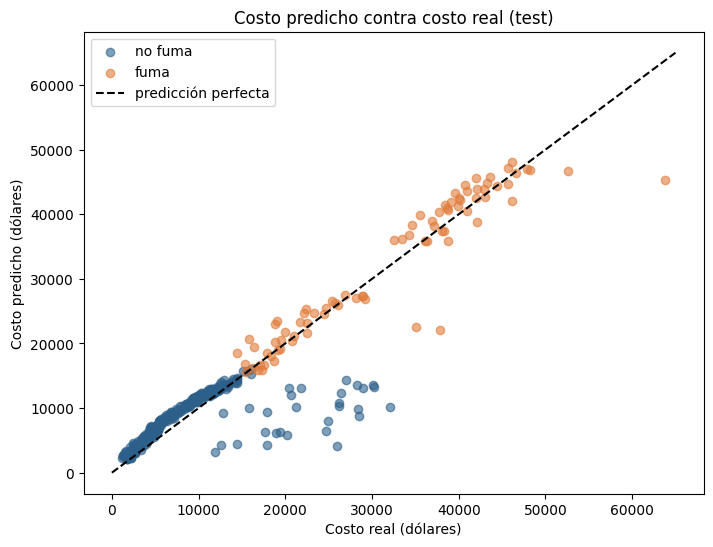

Personas con costo real más de 5.000 dólares por encima de lo predicho: 32 de 402 | de ellas no fuman: 28
Personas con costo real más de 5.000 dólares por debajo de lo predicho: 0


In [74]:
fuma = X_test_i['smoker'] == 1
no_fuma = X_test_i['smoker'] == 0

plt.figure(figsize=(8, 6))
plt.scatter(y_test_i[no_fuma], pred_test_i[no_fuma], color=AZUL, alpha=0.6, label='no fuma')
plt.scatter(y_test_i[fuma], pred_test_i[fuma], color=NARANJA, alpha=0.6, label='fuma')
plt.plot([0, 65000], [0, 65000], color='black', linestyle='--', label='predicción perfecta')
plt.xlabel('Costo real (dólares)')
plt.ylabel('Costo predicho (dólares)')
plt.title('Costo predicho contra costo real (test)')
plt.legend()
plt.show()

residuos = y_test_i - pred_test_i
print('Personas con costo real más de 5.000 dólares por encima de lo predicho:', (residuos > 5000).sum(),
      'de', len(residuos), '| de ellas no fuman:', ((residuos > 5000) & no_fuma).sum())
print('Personas con costo real más de 5.000 dólares por debajo de lo predicho:', (residuos < -5000).sum())

#### Conclusiones de la evaluación en test
* El modelo generaliza bien. El RMSE en test (**4.334** dólares) es parecido al de la validación cruzada (**4.561**), incluso un poco mejor. La diferencia está dentro de la variación normal entre particiones, así que no hay sobreajuste.
* Frente a predecir siempre el costo promedio (RMSE de **11.921** dólares), el error baja un **64%**. El R² de **0,868** indica que el modelo explica el 87% de la variación del costo, y el MAE dice que el error típico es de **2.434** dólares por persona.
* El modelo nunca sobreestima por mucho, porque no hay ningún caso con más de 5.000 dólares de error hacia abajo. En cambio, **32** de las 402 personas cuestan más de 5.000 dólares por encima de lo predicho, y **28** de ellas no fuman. En el gráfico forman una banda por encima de la diagonal. Probablemente tengan alguna enfermedad o internación que no está en el dataset, así que con estas variables ningún modelo podría predecir esos casos.

## B9. Entrenamiento con todos los datos disponibles

Entrenamos el modelo elegido con todos los datos (train y test, **1.337** personas) y las mismas 5 variables. En la regresión lineal estandarizar no cambia las predicciones, solo la unidad de los coeficientes. Por eso el modelo final lo entrenamos sin estandarizar, así cada coeficiente se lee directamente en dólares.

In [75]:
modelo_final_i = LinearRegression()
modelo_final_i.fit(X_i[sel_rf_i], y_i)
print('Modelo final entrenado con', len(X_i), 'personas')
print(f'Término independiente: {modelo_final_i.intercept_:.0f} dólares')
pd.DataFrame({'dólares que suma cada unidad': modelo_final_i.coef_.round(0)}, index=sel_rf_i)

Modelo final entrenado con 1337 personas
Término independiente: -3954 dólares


,dólares que suma cada unidad
fumador_obeso,19530.0
age,264.0
smoker,13567.0
bmi,47.0
children,500.0


In [76]:
casos = pd.DataFrame({'age': [45, 45, 45],
                      'bmi': [26, 26, 34],
                      'children': [2, 2, 2],
                      'smoker': [0, 1, 1],
                      'fumador_obeso': [0, 0, 1]},
                     index=['45 años, no fuma, IMC 26', '45 años, fuma, IMC 26', '45 años, fuma, IMC 34'])
casos['costo estimado (dólares)'] = modelo_final_i.predict(casos[sel_rf_i]).round(0)
casos

,age,bmi,children,smoker,fumador_obeso,costo estimado (dólares)
"45 años, no fuma, IMC 26",45,26,2,0,0,10159.0
"45 años, fuma, IMC 26",45,26,2,1,0,23726.0
"45 años, fuma, IMC 34",45,34,2,1,1,43629.0


* Cada año de edad suma **264** dólares, cada hijo **500** y cada punto de IMC apenas **47**.
* Fumar suma **13.567** dólares por año.
* Ser fumador con obesidad suma otros **19.530** dólares. Un fumador con IMC mayor a 30 cuesta unos 33.000 dólares más que alguien de la misma edad que no fuma.

Los tres casos de ejemplo lo muestran. La misma persona de 45 años pasa de **10.159** dólares a **23.726** si fuma, y a **43.629** si además tiene obesidad.

# Conclusiones

## Resumen de los 12 modelos

In [77]:
print('Clasificación (AUC medio, K-Fold con 10 particiones sobre train)')
print(tabla_t.round(3))
print()
print('Regresión (RMSE en dólares, K-Fold con 10 particiones sobre train)')
print(tabla_i[['modelo', 'conjunto', 'RMSE (dólares)', 'desvío del RMSE']].round(0))

Clasificación (AUC medio, K-Fold con 10 particiones sobre train)
               modelo        conjunto  AUC medio  desvío
0  LogisticRegression  Base (23 var.)      0.848   0.017
1          GaussianNB  Base (23 var.)      0.836   0.024
2  LogisticRegression   RFE (10 var.)      0.848   0.019
3          GaussianNB   RFE (10 var.)      0.829   0.027
4  LogisticRegression  PCA (15 comp.)      0.847   0.018
5          GaussianNB  PCA (15 comp.)      0.827   0.017

Regresión (RMSE en dólares, K-Fold con 10 particiones sobre train)
             modelo                conjunto  RMSE (dólares)  desvío del RMSE
0  LinearRegression          Base (10 var.)          4557.0            884.0
1               KNN          Base (10 var.)          5544.0            644.0
2  LinearRegression  Random Forest (5 var.)          4561.0            889.0
3               KNN  Random Forest (5 var.)          5140.0            656.0
4  LinearRegression           PCA (7 comp.)          4575.0            843.0
5     

## Clasificación (Telco Customer Churn)

1. El modelo más adecuado es la **regresión logística con las 10 variables de RFE**. Comparte el mejor AUC de los 6 modelos (**0,848**), en test mantuvo el mismo nivel (**0,846**) y usa 13 variables menos que el modelo base.
2. El modelo lineal superó a Naive Bayes con los tres conjuntos de variables. Con las variables transformadas, la separación entre los que se van y los que se quedan es aproximadamente lineal.
3. RFE redujo de 23 a 10 variables sin perder rendimiento. PCA necesitó 15 componentes, no mejoró y hace perder la interpretación.
4. La limitación principal la muestra el reporte de clasificación. Cuando el modelo marca a alguien como baja acierta el 67% de las veces, pero detecta solo la **mitad** de las bajas.
5. Con clases desbalanceadas el accuracy engaña, porque decir siempre No ya da 73,5%. Por eso comparamos con roc_auc y miramos precision y recall por clase.
6. El contrato mes a mes, la fibra óptica y el pago con cheque electrónico aumentan el riesgo de baja. Los contratos largos y la antigüedad lo reducen.

## Regresión (Medical Cost Personal)

1. El modelo más adecuado es la **regresión lineal con las 5 variables de Random Forest**. Empata con el mejor modelo de la comparación (RMSE de **4.561** dólares en validación cruzada), en test dio **4.334** dólares con un R² de **0,868** y sus coeficientes están en dólares.
2. La mejora más importante salió del EDA. La dispersión separada por **smoker** mostró el salto del costo en los fumadores con IMC mayor a 30. Al convertirlo en la variable **fumador_obeso**, un modelo lineal pudo representarlo y superó a KNN.
3. La importancia con Random Forest permitió usar la mitad de las variables sin perder rendimiento. PCA necesitó 7 de 10 componentes y no mejoró.
4. Lo que más determina el costo es fumar, y más todavía fumar con obesidad, seguido de la edad. El sexo y la región casi no influyen.

## Conclusiones generales

* En los dos problemas ganó un modelo lineal bien preparado. Rindió igual o mejor que el no lineal, es más rápido y es más fácil de explicar.
* Lo que más rindió fue entender los datos, con la limpieza en clasificación y la variable **fumador_obeso** en regresión.
* La selección de variables (RFE e importancia con Random Forest) dio modelos más simples sin perder rendimiento. PCA no mejoró en ninguno de los dos problemas y es sensible a la escala, así que hay que estandarizar todas las variables antes de aplicarlo.
* En los dos problemas el resultado en test coincidió con el de la validación cruzada, lo que indica que las estimaciones fueron confiables.

## Limitaciones

* No se optimizaron hiperparámetros, porque la consigna excluye esa etapa. Los modelos que más dependen de ellos (KNN, SVM y árboles) pueden haber quedado en desventaja.
* Las transformaciones, RFE y la importancia con Random Forest se ajustaron con todo train antes de la validación cruzada, como en las clases. Eso puede hacer la validación levemente optimista, aunque en los dos problemas el resultado en test fue igual o mejor.
* En clasificación los datos son de un solo período de una sola empresa (un dataset de ejemplo de IBM) y no hay información de lo que pasó antes de cada baja, como reclamos o cortes de servicio. Con el umbral por defecto se escapa la mitad de las bajas.
* En regresión faltan variables clave del costo médico, como enfermedades previas o internaciones. Eso explica el grupo de personas que cuestan mucho más de lo predicho. Además, el dataset es de un libro de texto y no de una aseguradora real.
* La idea de crear **fumador_obeso** salió de mirar todo el dataset en el EDA. El umbral de IMC 30 es un corte médico fijo, así que no usa información de test.

## Posibles mejoras

* Optimizar hiperparámetros con GridSearchCV, por ejemplo C y class_weight en la regresión logística o la cantidad de vecinos en KNN.
* En clasificación, elegir el umbral de decisión según el costo real de cada error. Con el mismo modelo, bajar el umbral de 0,5 a 0,35 detecta el **70%** de las bajas en lugar del **50%**, y la accuracy baja de **0,802** a **0,775**.
* Conseguir datos nuevos, como reclamos o cortes de servicio, más que crear variables con los que ya hay. Probamos sumar la cantidad de servicios contratados y marcar a los clientes con menos de un año, y el AUC no cambió, porque esa información ya está en **tenure** y en los servicios.
* En regresión, sumar datos de historia clínica. Agregar la edad al cuadrado solo bajó el RMSE de validación de 4.561 a 4.525 dólares.
* Probar ensambles con hiperparámetros ajustados. Un Random Forest con la configuración por defecto dio un AUC en test de **0,817**, menor que el de la regresión logística.
* Validar los modelos con datos nuevos de otro período antes de usarlos.